# 🎯 Tarea 7 — Encoder EGAT para el WTAP: el problema como grafo, ablación de profundidad y comparación

**Reemplazamos el encoder de nuestro mejor modelo de la Tarea 6 por una red atencional de grafos con aristas (EGAT) sobre el grafo bipartito armas–objetivos, y medimos cuánto importa la profundidad (número de saltos).**

En la Tarea 6 el mejor modelo fue la **Base** (menor gap medio en los 7 tamaños evaluados y el más barato): un encoder que lee una sola vez la instancia (atención cruzada armas ↔ objetivos con producto punto y la probabilidad $p_{ij}$ inyectada como arista) y un decoder que, en cada paso, integra el estado y puntúa los pares arma → objetivo. Aquí mantenemos **ese mismo decoder** y cambiamos solo el encoder por capas **EGAT** (atención aditiva de Veličković et al., 2018, con la arista en el puntaje y en el mensaje, como en el material del curso). Así la comparación aísla el efecto del encoder.

| Sección | Contenido | Punto de la tarea |
|---|---|---|
| 2 | Problema, entorno, MMR y experto ILS (código de las tareas anteriores) | — |
| 3 | El WTAP como grafo bipartito $G = (V, E)$ | 1 |
| 4 | Datos: trayectorias del experto (*teacher forcing*) | 3 |
| 5 | Encoder EGAT con el decoder de la Tarea 6; chequeos (GAT vs EGAT, campo receptivo) | 2 |
| 6 | Entrenamiento con la misma configuración de la Tarea 6 | 3 |
| 7 | Convergencia | 5 |
| 8 | Evaluación con instancias de distintos tamaños (gap vs experto ILS) | 6 |
| 9 | Ablación de profundidad: 1, 2 y 3 capas EGAT (saltos) | 4 |
| 10 | Discusión y conclusiones | — |

> ⏱️ La ejecución completa (`RAPIDO = False`, 3 semillas por modelo) tomó 51 min en CPU con 4 hilos: 47 min de entrenamiento (12, 8, 12 y 15 min para T6-Base, EGAT-1, EGAT-2 y EGAT-3) y unos 5 min de datos y evaluación. Con `RAPIDO = True` (menos datos, 1 semilla) corre en pocos minutos. Si hay GPU se usa para entrenar.

## 1. Instalación y librerías

Usamos la librería del curso [`eda`](https://github.com/rilianx/eda) para el `GreedyAgent` y el `SingleAgentSolver`, igual que en las tareas anteriores.

In [1]:
!test -d eda || git clone -q https://github.com/rilianx/eda.git

In [2]:
import os, json, time, copy, random, itertools, math, statistics
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from copy import deepcopy

from eda.agents import SingleAgentSolver, GreedyAgent
from eda.utils import handle_multiple_states

RAPIDO = False                         # True: 1 500 instancias, 1 semilla y 15 épocas (para probar el notebook)
N_SEEDS = 1 if RAPIDO else 3           # semillas de inicialización por modelo (estabilidad de la convergencia)
N_WEAPONS, N_TARGETS = 10, 8           # tamaño de ENTRENAMIENTO (el mismo de las Tareas 4-5 y del proyecto)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_THREADS = torch.get_num_threads()
print("Dispositivo:", device, "| hilos de CPU:", N_THREADS)

os.makedirs("figuras_t7", exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(f"figuras_t7/{nombre}.png", dpi=160, bbox_inches="tight")

# nombre en tablas -> encoder y número de capas; el decoder es siempre el de la Base de la Tarea 6
MODELOS = {"T6 · Base": dict(encoder="t6", n_layers=2),
           "EGAT · 1 capa": dict(encoder="egat", n_layers=1),
           "EGAT · 2 capas": dict(encoder="egat", n_layers=2),
           "EGAT · 3 capas": dict(encoder="egat", n_layers=3)}
CORTO = {"T6 · Base": "T6", "EGAT · 1 capa": "EGAT-1", "EGAT · 2 capas": "EGAT-2", "EGAT · 3 capas": "EGAT-3"}
COLORES = {"T6 · Base": "tab:blue", "EGAT · 1 capa": "#74c476", "EGAT · 2 capas": "#31a354",
           "EGAT · 3 capas": "#00592a", "MMR": "tab:orange", "Aleatorio": "tab:gray", "Módulo 2": "#9db4d6"}

Dispositivo: cpu | hilos de CPU: 4


## 2. El problema, el entorno, MMR y el experto (código del módulo 2)

$W$ armas y $T$ objetivos; el objetivo $j$ vale $V_j$ y el arma $i$ lo destruye con probabilidad $p_{ij}$. Cada arma se asigna a un objetivo y se minimiza el valor esperado que sobrevive:

$$\min_x \; Z = \sum_{j=1}^{T} V_j \prod_{i=1}^{W} (1 - p_{ij})^{x_{ij}}, \qquad q_j = \prod_i (1-p_{ij})^{x_{ij}} \;\text{(prob. de que } j \text{ sobreviva)}$$

Instancias de la literatura (Ahuja et al., 2007): $V_j \sim U\{25,\dots,100\}$, $p_{ij} \sim U(0{,}6;\,0{,}9)$. La acción constructiva es un **par** (arma libre $i$ → objetivo $j$); con $k$ armas libres hay $k\cdot T$ acciones. Las funciones de esta sección se copian **sin cambios** del notebook del proyecto: entorno, **MMR** (en cada paso el par con mayor ganancia marginal $g_{ij} = V_j\,q_j\,p_{ij}$), el **experto ILS** (MMR + búsqueda local `reassign`/`swap` + perturbación; en las tareas anteriores alcanzó el óptimo exacto en todas las instancias verificadas de 5×4 y 10×8) y la **descomposición** de su solución en W decisiones (en cada paso, el par del experto con mayor ganancia marginal). Del entorno dejamos solo las acciones constructivas, que son las que usa el agente.

In [3]:
class WTAP_Instance:
    def __init__(self, values, probs):
        self.values = np.asarray(values, dtype=float)   # V_j,  forma (T,)
        self.probs  = np.asarray(probs,  dtype=float)   # p_ij, forma (W, T)
        self.n_weapons, self.n_targets = self.probs.shape

    @staticmethod
    def random(n_weapons=N_WEAPONS, n_targets=N_TARGETS, rng=np.random):
        values = rng.randint(25, 101, size=n_targets).astype(float)
        probs  = rng.uniform(0.6, 0.9, size=(n_weapons, n_targets))
        return WTAP_Instance(values, probs)


class WTAP_State:
    # assignment[i] = objetivo asignado al arma i (-1 si el arma i aún está libre)
    def __init__(self, inst_info, assignment=None):
        self.inst_info = inst_info
        self.assignment = list(assignment) if assignment is not None else [-1] * inst_info.n_weapons
        self.update_cost()

    def update_cost(self):
        P = self.inst_info.probs
        self.q = np.ones(self.inst_info.n_targets)
        for i, j in enumerate(self.assignment):
            if j >= 0:
                self.q[j] *= 1 - P[i, j]
        self.cost = float(self.inst_info.values @ self.q)
        return self.cost

    @property
    def free_weapons(self):
        return [i for i, j in enumerate(self.assignment) if j < 0]

    @property
    def is_complete(self):
        return all(j >= 0 for j in self.assignment)

    def __deepcopy__(self, memo):
        return type(self)(self.inst_info, list(self.assignment))


class WTAP_Environment:
    @staticmethod
    def gen_actions(state, type, shuffle=False):
        if type != "constructive":
            raise NotImplementedError(f"Tipo de acción '{type}' no implementado")
        actions = [("constructive", (i, j)) for i in state.free_weapons for j in range(state.inst_info.n_targets)]
        if shuffle:
            random.shuffle(actions)
        for action in actions:
            yield action

    @staticmethod
    def state_transition(state, action):
        P, V = state.inst_info.probs, state.inst_info.values
        kind, (i, j) = action
        if kind != "constructive" or state.assignment[i] >= 0:
            raise NotImplementedError(f"Movimiento '{action}' no válido")
        state.assignment[i] = j
        state.q[j] *= 1 - P[i, j]
        state.cost = float(V @ state.q)
        return state


def cost_of(inst, assignment):
    P = inst.probs
    q = np.ones(inst.n_targets)
    for i, j in enumerate(assignment):
        if j >= 0:
            q[j] *= 1 - P[i, j]
    return float(inst.values @ q)

env = WTAP_Environment


@handle_multiple_states
def evalConstructiveActions(state, env):
    # MMR: ganancia marginal V_j * q_j * p_ij de cada par (arma libre i, objetivo j)
    V, P = state.inst_info.values, state.inst_info.probs
    return [(a, V[a[1][1]] * state.q[a[1][1]] * P[a[1][0], a[1][1]]) for a in env.gen_actions(state, "constructive")]


def mmr(inst):
    V, P = inst.values, inst.probs
    q = np.ones(inst.n_targets)
    assignment = [-1] * inst.n_weapons
    free = list(range(inst.n_weapons))
    while free:
        gains = (V * q)[None, :] * P[free]
        r, j = np.unravel_index(np.argmax(gains), gains.shape)
        i = free.pop(r)
        assignment[i] = int(j)
        q[j] *= 1 - P[i, j]
    return assignment


def q_of(P, a, T):
    q = np.ones(T)
    np.multiply.at(q, a, 1 - P[np.arange(len(a)), a])
    return q


def local_search(V, P, a, q):
    # best improvement con vecindarios reassign + swap (deltas vectorizados)
    W, T = P.shape
    idx = np.arange(W)
    while True:
        pa = P[idx, a]
        removal = V[a] * q[a] * pa / (1 - pa)
        delta_re = removal[:, None] - (V * q)[None, :] * P
        delta_re[idx, a] = np.inf
        term = (V[a] * q[a])[:, None] * ((1 - P[:, a].T) / (1 - pa)[:, None] - 1)
        delta_sw = term + term.T
        delta_sw[a[:, None] == a[None, :]] = np.inf
        best_re, best_sw = delta_re.min(), delta_sw.min()
        if min(best_re, best_sw) > -1e-9:
            return a, q
        if best_re <= best_sw:
            i, j = np.unravel_index(np.argmin(delta_re), delta_re.shape)
            q[a[i]] /= 1 - P[i, a[i]]; q[j] *= 1 - P[i, j]; a[i] = j
        else:
            i, k = np.unravel_index(np.argmin(delta_sw), delta_sw.shape)
            ai, ak = a[i], a[k]
            q[ai] *= (1 - P[k, ai]) / (1 - P[i, ai])
            q[ak] *= (1 - P[i, ak]) / (1 - P[k, ak])
            a[i], a[k] = ak, ai


def ils(inst, n_iter=100, k_perturb=3, rng=None):
    # experto: MMR + búsqueda local + perturbación de 3 armas; acepta si mejora (o con prob. 5 %)
    rng = rng or np.random.default_rng()
    V, P = inst.values, inst.probs
    W, T = P.shape
    a = np.array(mmr(inst))
    a, q = local_search(V, P, a, q_of(P, a, T))
    cur_cost = V @ q
    best_a, best_cost = a.copy(), cur_cost
    for _ in range(n_iter):
        b = a.copy()
        ws = rng.choice(W, size=k_perturb, replace=False)
        b[ws] = rng.integers(0, T, size=k_perturb)
        b, qb = local_search(V, P, b, q_of(P, b, T))
        cb = V @ qb
        if cb < cur_cost - 1e-12 or rng.random() < 0.05:
            a, cur_cost = b, cb
        if cb < best_cost - 1e-12:
            best_a, best_cost = b.copy(), cb
    return [int(x) for x in best_a], cost_of(inst, best_a)


def decompose(inst, expert_assignment):
    # (estado, acciones posibles, acción escogida); orden: par del experto con mayor ganancia marginal
    V, P, a = inst.values, inst.probs, expert_assignment
    state = WTAP_State(inst)
    while not state.is_complete:
        free = state.free_weapons
        gains = [V[a[i]] * state.q[a[i]] * P[i, a[i]] for i in free]
        i = free[int(np.argmax(gains))]
        chosen = ("constructive", (i, a[i]))
        yield deepcopy(state), list(env.gen_actions(state, "constructive")), chosen
        env.state_transition(state, chosen)


def solve_instances(n_weapons, n_targets, n_instances, seed):
    # instancias aleatorias resueltas por el experto (mismas semillas que en las tareas anteriores)
    rng, rng_ils = np.random.RandomState(seed), np.random.default_rng(seed)
    solved = []
    for _ in range(n_instances):
        inst = WTAP_Instance.random(n_weapons, n_targets, rng=rng)
        expert_assignment, expert_cost = ils(inst, rng=rng_ils)
        solved.append((inst, expert_assignment, expert_cost))
    return solved


def gap(costs, expert_costs):
    return 100 * (np.asarray(costs) / np.asarray(expert_costs) - 1)


def make_random_eval(seed):
    # constructivo aleatorio: puntajes uniformes, el GreedyAgent elige un par válido al azar
    rng = np.random.default_rng(seed)
    @handle_multiple_states
    def evalRandomActions(state, env):
        return [(action, rng.random()) for action in env.gen_actions(state, "constructive")]
    return evalRandomActions


def agent_costs(eval_actions, instances):
    # rollout con el GreedyAgent de eda para muchas instancias a la vez
    finals, *_ = SingleAgentSolver(env, GreedyAgent(eval_actions)).multistate_solve([WTAP_State(i) for i in instances])
    assert all(s.is_complete for s in finals)
    return np.array([s.cost for s in finals])


mmr_agent = SingleAgentSolver(env, GreedyAgent(evalConstructiveActions))
rng = np.random.RandomState(5)
for _ in range(20):
    inst = WTAP_Instance.random(rng=rng)
    assert mmr_agent.solve(WTAP_State(inst))[0].assignment == mmr(inst)
print("✔ GreedyAgent(evalConstructiveActions) reproduce exactamente a MMR")

✔ GreedyAgent(evalConstructiveActions) reproduce exactamente a MMR


## 3. Punto 1 — El WTAP como grafo bipartito $G = (V, E)$

El WTAP no trae un grafo explícito, pero su estructura es naturalmente **bipartita**: hay dos tipos de entidades (armas y objetivos) y toda la información que las relaciona está en la probabilidad $p_{ij}$ de que el arma $i$ destruya al objetivo $j$.

**Nodos** ($|V| = W + T$, dos tipos):

| Tipo | Qué representa | Features estáticas (encoder) | Estado dinámico (decoder, en cada paso) |
|---|---|---|---|
| Arma $i$ | un arma que hay que asignar | **ninguna**: todas parten del mismo vector aprendible (token compartido) | libre / ya asignada (máscara) |
| Objetivo $j$ | un objetivo enemigo | valor normalizado $V_j/\max V$ | $q_j$ (prob. de que sobreviva), $v_j q_j$, $\ln(v_j q_j)$ |

**Aristas** ($|E| = W\cdot T$): existe la arista $(i, j)$ entre el arma $i$ y el objetivo $j$ si el arma puede atacar al objetivo ($p_{ij} > 0$). En nuestras instancias $p_{ij} \in [0{,}6;\,0{,}9]$, así que el grafo es **bipartito completo** $K_{W,T}$ y sus aristas coinciden con las acciones del decoder. No hay aristas arma–arma ni objetivo–objetivo. El grafo es **no dirigido** (la relación es simétrica), pero el paso de mensajes la recorre **en ambos sentidos** (armas ← objetivos y objetivos ← armas), con parámetros distintos en cada sentido. **Atributo de la arista:** $\tilde p_{ij} = (p_{ij} - 0{,}75)/0{,}15 \in [-1, 1]$, una escala fija que no depende del tamaño de la instancia. Como en la definición de GAT, cada nodo tiene además un **auto-bucle** (con un atributo aprendido) para considerarse a sí mismo al agregar.

**¿Por qué esta representación?** Es la misma idea del MKP del material (ítems ↔ restricciones; Gasse et al., 2019): no depende del número de armas ni de objetivos, ni de su orden, así que un mismo modelo sirve para instancias de cualquier tamaño.

**Saltos (hops).** En $K_{W,T}$ un arma alcanza a todos los objetivos en 1 salto y a todas las demás armas en 2 saltos (a través de los objetivos que comparten): el **diámetro es 2**. Con 1 capa EGAT un arma conoce los objetivos que puede atacar; con 2 capas conoce además a las armas que compiten por ellos; una 3.ª capa ya no alcanza nodos nuevos, solo combina más veces la misma información.

Instancia 3×2: |V| = 5 nodos (3 armas + 2 objetivos) · |E| = 6 aristas (= W·T acciones)
  arma 1 — objetivo 1:  p = 0.83   p̃ = +0.56
  arma 1 — objetivo 2:  p = 0.73   p̃ = -0.12
  arma 2 — objetivo 1:  p = 0.82   p̃ = +0.45
  arma 2 — objetivo 2:  p = 0.89   p̃ = +0.96
  arma 3 — objetivo 1:  p = 0.76   p̃ = +0.08
  arma 3 — objetivo 2:  p = 0.75   p̃ = +0.00
  valores de los objetivos V: [72.0, 93.0]

Saltos desde el arma 1 en K_{4,3}: arma 1: 0, objetivo 1: 1, objetivo 2: 1, objetivo 3: 1, arma 2: 2, arma 3: 2, arma 4: 2
Diámetro de K_{W,T} (con W, T ≥ 2): 2


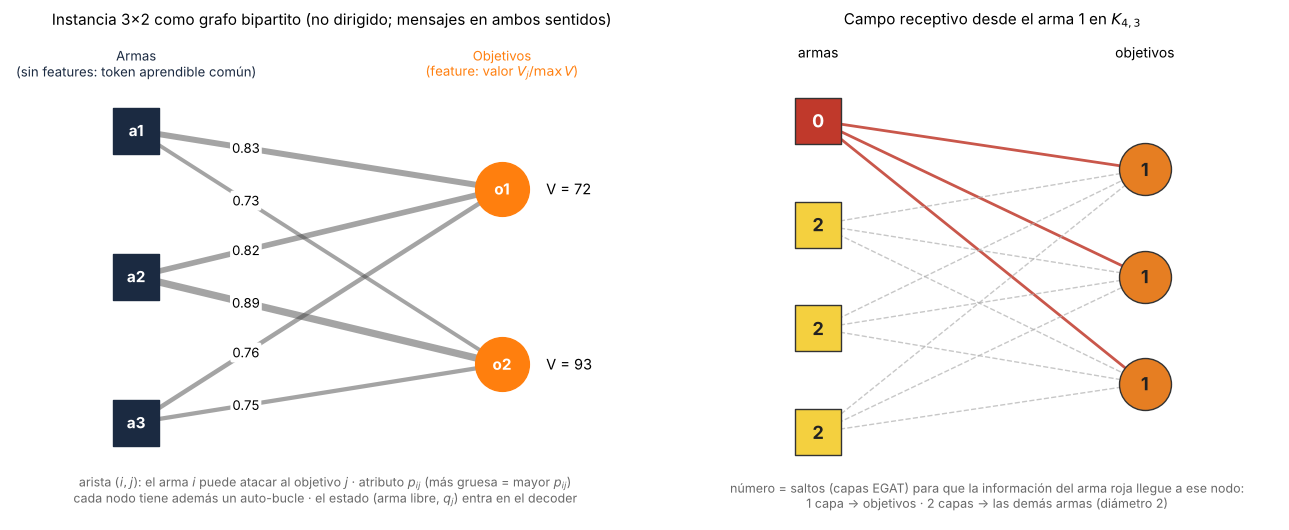

In [4]:
def grafo_bipartito(inst):
    # nodos de los dos tipos y aristas (i, j, p_ij) para todo par con p_ij > 0
    W, T = inst.probs.shape
    nodos = [("arma", i) for i in range(W)] + [("objetivo", j) for j in range(T)]
    aristas = [(i, j, float(inst.probs[i, j])) for i in range(W) for j in range(T) if inst.probs[i, j] > 0]
    return nodos, aristas


def saltos_desde(W, T, origen):
    # búsqueda en anchura en K_{W,T}: cuántos saltos separan al nodo de origen de cada nodo
    vecinos = lambda n: [("objetivo", j) for j in range(T)] if n[0] == "arma" else [("arma", i) for i in range(W)]
    dist, frontera = {origen: 0}, [origen]
    while frontera:
        nueva = []
        for n in frontera:
            for m in vecinos(n):
                if m not in dist:
                    dist[m] = dist[n] + 1
                    nueva.append(m)
        frontera = nueva
    return dist


inst_g = WTAP_Instance.random(3, 2, rng=np.random.RandomState(7))
nodos, aristas = grafo_bipartito(inst_g)
print(f"Instancia 3×2: |V| = {len(nodos)} nodos (3 armas + 2 objetivos) · |E| = {len(aristas)} aristas (= W·T acciones)")
for i, j, p in aristas:
    print(f"  arma {i + 1} — objetivo {j + 1}:  p = {p:.2f}   p̃ = {(p - 0.75) / 0.15:+.2f}")
print("  valores de los objetivos V:", inst_g.values.tolist())
d_arma = saltos_desde(4, 3, ("arma", 0))
print("\nSaltos desde el arma 1 en K_{4,3}:", ", ".join(f"{t} {k + 1}: {v}" for (t, k), v in d_arma.items()))
DIAMETRO = max(max(saltos_desde(4, 3, n).values()) for n in [("arma", 0), ("objetivo", 0)])
print("Diámetro de K_{W,T} (con W, T ≥ 2):", DIAMETRO)

# ---- diagrama: la instancia 3×2 y el campo receptivo por saltos en K_{4,3}
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), gridspec_kw={"width_ratios": [1.12, 1]})
ax = axes[0]
W_, T_ = inst_g.probs.shape
yw, yt, xw, xt = np.linspace(0.80, 0.20, W_), np.linspace(0.68, 0.32, T_), 0.20, 0.78
for i in range(W_):
    for j in range(T_):
        p = inst_g.probs[i, j]
        ax.plot([xw, xt], [yw[i], yt[j]], color="#4a4a4a", lw=0.8 + 4.5 * (p - 0.6) / 0.3, alpha=0.5, zorder=1)
        f = 0.30
        ax.text(xw + f * (xt - xw), yw[i] + f * (yt[j] - yw[i]), f"{p:.2f}", fontsize=9.5, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"), zorder=3)
for i in range(W_):
    ax.scatter([xw], [yw[i]], s=1100, marker="s", color="#1B2A41", zorder=4)
    ax.text(xw, yw[i], f"a{i + 1}", color="white", ha="center", va="center", fontsize=11, weight="bold", zorder=5)
for j in range(T_):
    ax.scatter([xt], [yt[j]], s=1500, marker="o", color="tab:orange", zorder=4)
    ax.text(xt, yt[j], f"o{j + 1}", color="white", ha="center", va="center", fontsize=11, weight="bold", zorder=5)
    ax.text(xt + 0.07, yt[j], f"V = {inst_g.values[j]:.0f}", ha="left", va="center", fontsize=10.5)
ax.text(xw, 0.97, "Armas\n(sin features: token aprendible común)", ha="center", va="top", fontsize=9.5, color="#1B2A41")
ax.text(xt, 0.97, "Objetivos\n(feature: valor $V_j/\\max V$)", ha="center", va="top", fontsize=9.5, color="tab:orange")
ax.text(0.5, 0.06, "arista $(i, j)$: el arma $i$ puede atacar al objetivo $j$ · atributo $p_{ij}$ (más gruesa = mayor $p_{ij}$)\n"
        "cada nodo tiene además un auto-bucle · el estado (arma libre, $q_j$) entra en el decoder",
        ha="center", va="center", fontsize=9, color="dimgray")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("Instancia 3×2 como grafo bipartito (no dirigido; mensajes en ambos sentidos)", fontsize=11)

ax = axes[1]
W4, T3 = 4, 3
yw4, yt3 = np.linspace(0.82, 0.18, W4), np.linspace(0.72, 0.28, T3)
col_salto = {0: "#c0392b", 1: "#e67e22", 2: "#f4d03f"}
for i in range(W4):
    for j in range(T3):
        primero = i == 0
        ax.plot([xw, xt], [yw4[i], yt3[j]], color="#c0392b" if primero else "#b0b0b0", lw=2.0 if primero else 1.0,
                ls="-" if primero else "--", alpha=0.85 if primero else 0.7, zorder=1)
for (tipo, k), s in d_arma.items():
    x, y = (xw, yw4[k]) if tipo == "arma" else (xt, yt3[k])
    ax.scatter([x], [y], s=1100 if tipo == "arma" else 1400, marker="s" if tipo == "arma" else "o",
               color=col_salto[s], edgecolor="#333", zorder=4)
    ax.text(x, y, str(s), ha="center", va="center", fontsize=13, weight="bold", zorder=5,
            color="white" if s == 0 else "#222")
ax.text(xw, 0.95, "armas", ha="center", fontsize=10); ax.text(xt, 0.95, "objetivos", ha="center", fontsize=10)
ax.text(0.5, 0.05, "número = saltos (capas EGAT) para que la información del arma roja llegue a ese nodo:\n"
        "1 capa → objetivos · 2 capas → las demás armas (diámetro 2)", ha="center", va="center", fontsize=9,
        color="dimgray")
ax.set_xlim(0, 1.02); ax.set_ylim(0, 1); ax.axis("off")
ax.set_title("Campo receptivo desde el arma 1 en $K_{4,3}$", fontsize=11)
plt.tight_layout(); guardar(fig, "grafo_wtap"); plt.show()
GRAFO = {"ejemplo": {"W": 3, "T": 2, "p": inst_g.probs.round(3).tolist(), "V": inst_g.values.tolist()},
         "n_nodos": "W + T", "n_aristas": "W·T", "diametro": DIAMETRO,
         "saltos_desde_arma": {f"{t} {k + 1}": v for (t, k), v in d_arma.items()}}

## 4. Datos: trayectorias del experto (*teacher forcing*)

Usamos **las mismas instancias y el mismo experto** que en las tareas anteriores: 6 000 instancias 10×8 de entrenamiento (semilla 0), 300 de validación (semilla 1) y 50 de prueba (semilla 2024). Lo que cambia es el formato. Como el encoder ya no depende del estado, una muestra es ahora **una instancia completa con sus W decisiones**: el encoder se ejecuta una vez por instancia y el decoder se evalúa en los W estados de la trayectoria del experto en paralelo (*teacher forcing*).

| Tensor | Forma | Contenido |
|---|---|---|
| `P` | (N, W, T) | probabilidades $p_{ij}$ (estático, al encoder) |
| `V` | (N, T) | valores $V_j$ (estático, al encoder) |
| `FREE` | (N, W pasos, W) | armas libres antes de cada decisión (estado, al decoder) |
| `Q` | (N, W pasos, T) | $q_j$ antes de cada decisión (estado, al decoder) |
| `Y` | (N, W pasos) | par escogido por el experto, codificado como $i\cdot T + j$ |

In [5]:
def trajectories(solved):
    # convierte instancias resueltas (todas del mismo tamaño) en tensores de teacher forcing
    N = len(solved)
    W, T = solved[0][0].probs.shape
    P = np.zeros((N, W, T), np.float32); V = np.zeros((N, T), np.float32)
    FREE = np.zeros((N, W, W), bool); Q = np.zeros((N, W, T), np.float32); Y = np.zeros((N, W), np.int64)
    for k, (inst, expert_assignment, _) in enumerate(solved):
        P[k], V[k] = inst.probs, inst.values
        for t, (state, actions, chosen) in enumerate(decompose(inst, expert_assignment)):
            FREE[k, t] = np.asarray(state.assignment) < 0
            Q[k, t] = state.q
            i, j = chosen[1]
            Y[k, t] = i * T + j
    return {"P": torch.tensor(P), "V": torch.tensor(V), "FREE": torch.tensor(FREE),
            "Q": torch.tensor(Q), "Y": torch.tensor(Y)}


N_TRAIN = 1500 if RAPIDO else 6000
t0 = time.time()
train_solved = solve_instances(N_WEAPONS, N_TARGETS, N_TRAIN, seed=0)
val_solved   = solve_instances(N_WEAPONS, N_TARGETS, 300, seed=1)
test_solved  = solve_instances(N_WEAPONS, N_TARGETS, 50, seed=2024)
D_train, D_val, D_test = trajectories(train_solved), trajectories(val_solved), trajectories(test_solved)
print(f"Datos generados en {time.time() - t0:.0f} s")
for name, D in [("train", D_train), ("val", D_val), ("test", D_test)]:
    print(f"{name:>5}: " + " | ".join(f"{k} {tuple(v.shape)}" for k, v in D.items()) + f"  -> {D['Y'].numel():,} decisiones")

val_insts = [inst for inst, _, _ in val_solved[:100]]          # 100 instancias para el gap de validación por época
val_expert = np.array([c for _, _, c in val_solved[:100]])
test_insts = [inst for inst, _, _ in test_solved]
test_expert = np.array([c for _, _, c in test_solved])
print(f"Costo medio del experto en las 50 de prueba: {test_expert.mean():.3f} (el mismo de las Tareas 4-5 y el proyecto: 46.263)")

# sanity checks: la etiqueta siempre es un par de un arma libre y q es consistente con las decisiones previas
for D in (D_train, D_val, D_test):
    N, W, T = D["P"].shape
    i_lab = D["Y"] // T
    assert D["FREE"].gather(2, i_lab.unsqueeze(-1)).all()                                  # arma de la etiqueta libre
    assert (D["FREE"].sum(-1) == (W - torch.arange(W)).unsqueeze(0)).all()                  # W - t armas libres
    q = torch.ones(N, T)
    for t in range(W):
        assert torch.allclose(D["Q"][:, t], q, atol=1e-5)
        i, j = D["Y"][:, t] // T, D["Y"][:, t] % T
        q[torch.arange(N), j] *= 1 - D["P"][torch.arange(N), i, j]
print("✔ Etiquetas válidas y estados q_j consistentes con las decisiones del experto")

Datos generados en 65 s
train: P (6000, 10, 8) | V (6000, 8) | FREE (6000, 10, 10) | Q (6000, 10, 8) | Y (6000, 10)  -> 60,000 decisiones
  val: P (300, 10, 8) | V (300, 8) | FREE (300, 10, 10) | Q (300, 10, 8) | Y (300, 10)  -> 3,000 decisiones
 test: P (50, 10, 8) | V (50, 8) | FREE (50, 10, 10) | Q (50, 10, 8) | Y (50, 10)  -> 500 decisiones
Costo medio del experto en las 50 de prueba: 46.263 (el mismo de las Tareas 4-5 y el proyecto: 46.263)
✔ Etiquetas válidas y estados q_j consistentes con las decisiones del experto


## 5. Punto 2 — Encoder EGAT con el decoder de la Tarea 6

**¿GAT o EGAT? EGAT.** En el WTAP las armas no tienen información propia: todas parten del mismo vector y lo único que las distingue son sus probabilidades $p_{ij}$, que viven en las aristas. Una GAT estándar solo mira los nodos, así que las $W$ armas quedarían idénticas en todas las capas (lo comprobamos abajo). La EGAT inyecta la arista en el puntaje de atención y en el mensaje, de modo que cada arma se diferencia desde la primera capa. Para no romper la invariancia a permutaciones, **no** usamos un vector distinto por índice de arma: todas comparten el mismo token aprendible (un vector por tipo de nodo, como sugiere el material).

**Una capa EGAT** en el grafo bipartito, para cada sentido (armas ← objetivos y objetivos ← armas, en paralelo, con 4 cabezas):

1. **Proyección** por tipo de nodo: $z_i = W_{\text{dst}}\,h_i$ (quien recibe), $z_j = W_{\text{src}}\,h_j$ (vecino) y la arista $E_{ij} = W_e\,\tilde p_{ij}$.
2. **Atención aditiva con la arista:** $e_{ij} = \mathrm{LeakyReLU}\big(a_L\cdot z_i + a_R\cdot z_j + a_E\cdot E_{ij}\big)$ (pendiente 0,2).
3. **Softmax local** sobre los vecinos **y el auto-bucle** del nodo: $\alpha_{ij} = \mathrm{softmax}_{j \in \mathcal N_i \cup \{i\}}(e_{ij})$; el auto-bucle usa $z_i$ y un atributo aprendido $E_{ii}$.
4. **Mensajes condicionados por la arista:** $h_i' = \big\Vert_{k=1}^{4} \sum_{j} \alpha^k_{ij}\,\big(z^k_j + E^k_{ij}\big)$, seguido de una proyección de salida.
5. **Estabilización** (igual que la Tarea 6): residual + LayerNorm, feed-forward 64→128→64, residual + LayerNorm.

Con $L$ capas, cada nodo integra información a $L$ saltos. Costo por capa: $O(W\,T\,d + (W+T)\,d^2)$, lineal en el número de aristas.

**Lo que no cambia:** la inicialización de los nodos (token aprendible compartido para las armas y $\mathrm{Linear}(V_j/\max V)$ para los objetivos), $d = 64$, 4 cabezas, FF de 128 y **todo el decoder** de la Base de la Tarea 6 (estado de los objetivos, contexto con promedios, glimpse y puntero aditivo por pares con la arista $p_{ij}$).

| Cambio | Tarea 6 (Base) | Tarea 7 (EGAT) |
|---|---|---|
| ① Grafo | implícito: atención armas ↔ objetivos | explícito: bipartito $K_{W,T}$ con atributo $\tilde p_{ij}$ y auto-bucles |
| ② Puntaje de atención | producto punto $q_i\cdot k_j/\sqrt{d_h} + \beta_h\,\tilde p_{ij}$ | aditivo $\mathrm{LeakyReLU}(a_L\cdot z_i + a_R\cdot z_j + a_E\cdot E_{ij})$ |
| ③ Proyecciones | tres matrices $W_Q, W_K, W_V$ | una $W$ por tipo de nodo, para el puntaje y el mensaje (como GAT) |
| ④ Arista | un escalar por cabeza en el puntaje y un vector en el mensaje | vector $E_{ij} = W_e\tilde p_{ij}$ en el puntaje (vía $a_E$) y en el mensaje |
| ⑤ Profundidad | 2 capas | $L$ = 1, 2 y 3 capas (ablación) |
| Decoder | — | **sin cambios** |

In [6]:
from functools import partial

D_MODEL, N_HEADS, N_LAYERS, D_FF, CLIP = 64, 4, 2, 128, 10.0         # misma configuración que la Tarea 6
NEG = -1e9


def p_scaled(P):
    # p_ij ~ U(0.6, 0.9) -> [-1, 1]  (escala fija: no depende de la instancia ni de su tamaño)
    return (P - 0.75) / 0.15


def feed_forward(d, d_ff):
    return nn.Sequential(nn.Linear(d, d_ff), nn.ReLU(), nn.Linear(d_ff, d))


class EdgeCrossAttention(nn.Module):
    # ENCODER DE LA TAREA 6 (sin cambios): MHA de producto punto de un conjunto sobre el otro, con la arista p_ij
    # en el puntaje (peso por cabeza) y en el mensaje (vector aprendido)
    def __init__(self, d, h):
        super().__init__()
        self.h, self.dh = h, d // h
        self.Wq = nn.Linear(d, d, bias=False)
        self.Wk = nn.Linear(d, d, bias=False)
        self.Wv = nn.Linear(d, d, bias=False)
        self.Wo = nn.Linear(d, d)
        self.edge_score = nn.Parameter(torch.zeros(h))
        self.edge_msg = nn.Linear(1, d)

    def forward(self, X, Y, E):
        # X: (B, Nx, d) queries · Y: (B, Ny, d) keys/values · E: (B, Nx, Ny) aristas escaladas
        B, Nx, d = X.shape
        Ny = Y.shape[1]
        q = self.Wq(X).view(B, Nx, self.h, self.dh).transpose(1, 2)            # (B, h, Nx, dh)
        k = self.Wk(Y).view(B, Ny, self.h, self.dh).transpose(1, 2)
        v = self.Wv(Y).view(B, Ny, self.h, self.dh).transpose(1, 2)
        s = q @ k.transpose(-1, -2) / self.dh ** 0.5                           # (B, h, Nx, Ny)
        s = s + self.edge_score.view(1, -1, 1, 1) * E.unsqueeze(1)             # + arista en el puntaje
        att = torch.softmax(s, dim=-1)
        out = att @ v
        e_mean = (att * E.unsqueeze(1)).sum(-1, keepdim=True)
        w = self.edge_msg.weight.view(1, self.h, 1, self.dh)
        b = self.edge_msg.bias.view(1, self.h, 1, self.dh)
        out = out + e_mean * w + b                                             # + mensajes de las aristas
        return self.Wo(out.transpose(1, 2).reshape(B, Nx, d))


class EGATConv(nn.Module):
    # TAREA 7: atención de grafo con aristas (GAT de Veličković et al. + EGAT del material) en el grafo bipartito.
    # Cada nodo que recibe (i) atiende a todos sus vecinos del otro tipo (j) y a sí mismo (auto-bucle):
    #   e_ij = LeakyReLU(a_L·z_i + a_R·z_j + a_E·E_ij),  z = W h,  E_ij = W_e p̃_ij
    #   h_i' = ||_k  sum_j softmax_j(e_ij) (z_j + E_ij)
    # edges=False -> GAT estándar (sin información de las aristas); solo se usa en el chequeo de abajo
    def __init__(self, d, h, edges=True, slope=0.2):
        super().__init__()
        self.h, self.dh, self.edges = h, d // h, edges
        self.W_dst = nn.Linear(d, d, bias=False)               # proyección del tipo de nodo que recibe
        self.W_src = nn.Linear(d, d, bias=False)               # proyección del tipo de nodo vecino
        self.a_L = nn.Parameter(torch.empty(1, h, 1, self.dh))
        self.a_R = nn.Parameter(torch.empty(1, h, 1, self.dh))
        nn.init.xavier_uniform_(self.a_L, gain=1.414)
        nn.init.xavier_uniform_(self.a_R, gain=1.414)
        if edges:
            self.W_e = nn.Linear(1, d, bias=False)             # arista escalar -> vector (por cabeza)
            self.a_E = nn.Parameter(torch.empty(1, h, 1, 1, self.dh))
            nn.init.xavier_uniform_(self.a_E, gain=1.414)
            self.e_self = nn.Parameter(torch.zeros(h, self.dh))   # atributo aprendido del auto-bucle
        self.leaky = nn.LeakyReLU(slope)
        self.out = nn.Linear(d, d)

    def forward(self, X, Y, E):
        # X: (B, Nx, d) nodos que reciben · Y: (B, Ny, d) vecinos (el otro tipo) · E: (B, Nx, Ny) aristas escaladas
        B, Nx, d = X.shape
        Ny, h, dh = Y.shape[1], self.h, self.dh
        zx = self.W_dst(X).view(B, Nx, h, dh).transpose(1, 2)                  # (B, h, Nx, dh)
        zy = self.W_src(Y).view(B, Ny, h, dh).transpose(1, 2)                  # (B, h, Ny, dh)
        s_L = (zx * self.a_L).sum(-1)                                          # perspectiva de quien recibe (B, h, Nx)
        s_R = (zy * self.a_R).sum(-1)                                          # perspectiva del vecino (B, h, Ny)
        e = s_L.unsqueeze(-1) + s_R.unsqueeze(-2)                              # (B, h, Nx, Ny)
        e_self = s_L + (zx * self.a_R).sum(-1)                                 # auto-bucle: el nodo como su vecino
        if self.edges:
            Ee = self.W_e(E.unsqueeze(-1)).view(B, Nx, Ny, h, dh).permute(0, 3, 1, 2, 4)   # (B, h, Nx, Ny, dh)
            e = e + (Ee * self.a_E).sum(-1)                                    # + perspectiva de la arista
            es = self.e_self.view(1, h, 1, dh)
            e_self = e_self + (es * self.a_E[:, :, 0]).sum(-1)
        alpha = torch.softmax(torch.cat([self.leaky(e), self.leaky(e_self).unsqueeze(-1)], -1), dim=-1)
        a_n, a_s = alpha[..., :Ny], alpha[..., Ny:]                            # vecinos (B, h, Nx, Ny) y auto-bucle
        out = a_n @ zy + a_s * zx                                              # mensajes de los nodos
        if self.edges:
            out = out + (a_n.unsqueeze(-1) * Ee).sum(-2) + a_s * es            # + mensajes de las aristas
        return self.out(out.transpose(1, 2).reshape(B, Nx, d))


ENCODERS = {"t6": EdgeCrossAttention, "egat": EGATConv, "gat": partial(EGATConv, edges=False)}


class BipartiteLayer(nn.Module):
    # una capa del encoder: armas <- objetivos y objetivos <- armas, en paralelo (misma estructura en T6 y T7)
    def __init__(self, d, h, d_ff, attn):
        super().__init__()
        self.att_w, self.att_t = attn(d, h), attn(d, h)
        self.ff_w, self.ff_t = feed_forward(d, d_ff), feed_forward(d, d_ff)
        self.n_w1, self.n_w2, self.n_t1, self.n_t2 = (nn.LayerNorm(d) for _ in range(4))

    def forward(self, Hw, Ht, E):
        mw = self.att_w(Hw, Ht, E)                               # cada arma recibe de los T objetivos
        mt = self.att_t(Ht, Hw, E.transpose(1, 2))               # cada objetivo recibe de las W armas
        Hw = self.n_w1(Hw + mw); Hw = self.n_w2(Hw + self.ff_w(Hw))
        Ht = self.n_t1(Ht + mt); Ht = self.n_t2(Ht + self.ff_t(Ht))
        return Hw, Ht


class StaticEncoder(nn.Module):
    # solo información estática: V_j y p_ij. Arma = token aprendible compartido; objetivo = Linear(V_j / max V)
    def __init__(self, d, h, n_layers, d_ff, attn):
        super().__init__()
        self.weapon_token = nn.Parameter(torch.randn(d) * 0.5)
        self.target_embed = nn.Linear(1, d)
        self.layers = nn.ModuleList([BipartiteLayer(d, h, d_ff, attn) for _ in range(n_layers)])

    def forward(self, P, V):
        B, W, T = P.shape
        E = p_scaled(P)
        Hw = self.weapon_token.expand(B, W, -1)
        Ht = self.target_embed((V / V.amax(1, keepdim=True)).unsqueeze(-1))
        for layer in self.layers:
            Hw, Ht = layer(Hw, Ht, E)
        return Hw, Ht


def target_state(V, q):
    # estado dinámico de cada objetivo: [q_j, v_j q_j, ln(v_j q_j)] con v = V / max V
    v = (V / V.amax(-1, keepdim=True)).unsqueeze(1)            # (B, 1, T)
    vq = v * q
    return torch.stack([q, vq, torch.log(vq.clamp_min(1e-12))], dim=-1), v, vq


class WTAPModel(nn.Module):
    # encoder: "t6" (atención bipartita de la Tarea 6) | "egat" (Tarea 7) | "gat" (solo para el chequeo)
    # decoder: el de la Base de la Tarea 6, sin cambios
    def __init__(self, encoder="egat", n_layers=N_LAYERS, d=D_MODEL, h=N_HEADS, d_ff=D_FF, clip=CLIP):
        super().__init__()
        self.d, self.clip = d, clip
        self.encoder = StaticEncoder(d, h, n_layers, d_ff, ENCODERS[encoder])
        # decoder (igual que la Base de la Tarea 6): estado de los objetivos, contexto + glimpse y puntero por pares
        self.state_mlp = nn.Sequential(nn.Linear(3, d), nn.ReLU(), nn.Linear(d, d))
        self.n_state = nn.LayerNorm(d)
        self.WA = nn.Linear(d, d, bias=False)
        self.WB = nn.Linear(d, d)
        self.WE = nn.Linear(1, d, bias=False)
        self.Wr = nn.Linear(d, d, bias=False)
        nn.init.zeros_(self.Wr.weight)          # logits iniciales = 0: política inicial uniforme
        self.Wc = nn.Linear(2 * d + 2, d)
        self.glimpse = nn.MultiheadAttention(d, h, batch_first=True)
        self.n_g1, self.n_g2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.ff_g = feed_forward(d, d_ff)

    # ------------------------------------------------------------ ENCODER: 1 vez por instancia
    def encode(self, P, V):
        Hw, Ht = self.encoder(P, V)
        # partes del puntero que no dependen del estado: se calculan aquí, una sola vez
        return {"Hw": Hw, "Ht": Ht, "A": self.WA(Hw), "Ep": self.WE(p_scaled(P).unsqueeze(-1)), "P": P, "V": V}

    # ------------------------------------------------------------ DECODER: cada paso (sin cambios)
    def decode(self, enc, free, q):
        # free: (B, S, W) armas libres · q: (B, S, T) prob. de sobrevivir -> logits (B, S, W·T)
        Hw, Ht, A, Ep, P, V = (enc[k] for k in ("Hw", "Ht", "A", "Ep", "P", "V"))
        B, S, W = free.shape
        T, d = Ht.shape[1], self.d
        s, v, vq = target_state(V, q)
        Hq = self.n_state(Ht.unsqueeze(1) + self.state_mlp(s))                      # (B, S, T, d)
        fr = free.float()
        k_free = fr.sum(-1, keepdim=True)
        glob = torch.cat([k_free / W, vq.sum(-1, keepdim=True) / v.sum(-1, keepdim=True)], -1)   # (B, S, 2)
        Z = torch.relu(A[:, None, :, None, :] + self.WB(Hq)[:, :, None, :, :] + Ep[:, None])    # pares (B, S, W, T, d)
        w_mean = (fr @ Hw) / k_free.clamp_min(1)                                     # media de armas libres
        c = self.Wc(torch.cat([w_mean, Hq.mean(2), glob], -1)).reshape(B * S, 1, d)
        keys = torch.cat([Hw.unsqueeze(1).expand(B, S, W, d), Hq], 2).reshape(B * S, W + T, d)
        kpm = torch.cat([~free, torch.zeros(B, S, T, dtype=torch.bool, device=free.device)], -1)
        g, _ = self.glimpse(c, keys, keys, key_padding_mask=kpm.reshape(B * S, W + T))   # glimpse
        c = self.n_g1(c + g)
        c = self.n_g2(c + self.ff_g(c)).reshape(B, S, d)
        u = (Z * self.Wr(c)[:, :, None, None, :]).sum(-1) / d ** 0.5                # (B, S, W, T)
        u = self.clip * torch.tanh(u)
        u = u.masked_fill(~free.unsqueeze(-1), NEG)                                  # máscara: armas ya usadas
        return u.reshape(B, S, W * T)

    def forward(self, P, V, free, q):
        return self.decode(self.encode(P, V), free, q)


def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

PARAMS = {name: (n_params(WTAPModel(**cfg)), n_params(WTAPModel(**cfg).encoder)) for name, cfg in MODELOS.items()}
print(f"{'Modelo':<16} {'parámetros':>11} {'de ellos, encoder':>18}")
for name, (tot, enc) in PARAMS.items():
    print(f"{name:<16} {tot:>11,} {enc:>18,}".replace(",", " "))

Modelo            parámetros  de ellos, encoder
T6 · Base            192 656            133 840
EGAT · 1 capa        118 016             59 200
EGAT · 2 capas       177 024            118 208
EGAT · 3 capas       236 032            177 216


In [7]:
# chequeos de los modelos SIN entrenar
torch.manual_seed(0)
xb = {k: v[:16] for k, v in D_train.items()}
for name, cfg in MODELOS.items():
    m = WTAPModel(**cfg).eval()
    with torch.no_grad():
        logits = m(xb["P"], xb["V"], xb["FREE"], xb["Q"])                                  # (16, W, W·T)
    probs = torch.softmax(logits, -1)
    valid = xb["FREE"].unsqueeze(-1).expand(-1, -1, -1, N_TARGETS).reshape(16, N_WEAPONS, -1)
    assert torch.allclose(probs.sum(-1), torch.ones(16, N_WEAPONS), atol=1e-5)
    assert probs[~valid].max() < 1e-12                                                    # pares inválidos con prob. 0
    ce = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), xb["Y"].reshape(-1)).item()
    ref = torch.log(valid.sum(-1).float()).mean().item()
    print(f"{name:<15} salida {tuple(logits.shape)} | CE inicial {ce:.3f} (uniforme: {ref:.3f})")

# el mismo modelo acepta cualquier tamaño, y el encoder no depende del estado
inst20 = WTAP_Instance.random(20, 15, rng=np.random.RandomState(5))
P20 = torch.tensor(inst20.probs, dtype=torch.float32)[None]
V20 = torch.tensor(inst20.values, dtype=torch.float32)[None]
m = WTAPModel("egat", 2).eval()
with torch.no_grad():
    enc = m.encode(P20, V20)                                          # 1 sola vez
    free = torch.ones(1, 3, 20, dtype=torch.bool); free[0, 1, :5] = False; free[0, 2, :12] = False
    out = m.decode(enc, free, torch.rand(1, 3, 15))                   # 3 estados distintos con el mismo encoder
print(f"\nInstancia 20×15 con EGAT: encoder 1 vez -> Hw {tuple(enc['Hw'].shape)}, Ht {tuple(enc['Ht'].shape)}; "
      f"decoder en 3 estados -> {tuple(out.shape)}; pares válidos por estado: {(out > -1e8).sum(-1).tolist()[0]}")

# ¿GAT o EGAT? Sin la información de las aristas, las armas (todas con el mismo token) no se pueden distinguir
inst6 = WTAP_Instance.random(6, 4, rng=np.random.RandomState(11))
P6 = torch.tensor(inst6.probs, dtype=torch.float32)[None]
V6 = torch.tensor(inst6.values, dtype=torch.float32)[None]


def max_dist(H):
    return (H[0][:, None] - H[0][None]).norm(dim=-1).max().item()

GAT_CHECK = {}
print()
for enc_name in ("gat", "egat"):
    torch.manual_seed(0)
    m = WTAPModel(enc_name, 3).eval()
    with torch.no_grad():
        Hw, Ht = m.encoder(P6, V6)
    GAT_CHECK[enc_name] = {"armas": max_dist(Hw), "objetivos": max_dist(Ht)}
    print(f"{enc_name.upper():<5} (3 capas, sin entrenar): distancia máxima entre los embeddings de las 6 armas = "
          f"{GAT_CHECK[enc_name]['armas']:.2e} | entre los 4 objetivos = {GAT_CHECK[enc_name]['objetivos']:.2e}")
assert GAT_CHECK["gat"]["armas"] < 1e-5 < 1e-2 < GAT_CHECK["egat"]["armas"]
print("✔ Con GAT las W armas quedan idénticas en todas las capas; con EGAT se diferencian por sus aristas p_ij")

# campo receptivo: ¿de qué aristas depende el embedding de un nodo después de L capas? (gradientes exactos)
# (se proyecta el embedding sobre un vector fijo: la suma directa de una salida de LayerNorm siempre vale 0)
r_proj = torch.randn(D_MODEL, generator=torch.Generator().manual_seed(1))
CAMPO = {}
print(f"\n{'capas':>5} {'arma 1 ← su fila p_1j':>22} {'arma 1 ← filas de otras armas':>31} "
      f"{'objetivo 1 ← su columna':>24} {'objetivo 1 ← otras columnas':>28}")
for L in (1, 2, 3):
    torch.manual_seed(0)
    encoder = WTAPModel("egat", L).encoder.eval()
    P = P6.clone().requires_grad_(True)
    Hw, Ht = encoder(P, V6)
    g_w = torch.autograd.grad((Hw[0, 0] * r_proj).sum(), P, retain_graph=True)[0][0]   # (W, T)
    g_t = torch.autograd.grad((Ht[0, 0] * r_proj).sum(), P)[0][0]
    CAMPO[L] = {"arma_fila_propia": g_w[0].norm().item(), "arma_otras_armas": g_w[1:].norm().item(),
                "objetivo_columna_propia": g_t[:, 0].norm().item(), "objetivo_otras_columnas": g_t[:, 1:].norm().item()}
    print(f"{L:>5} " + " ".join(f"{CAMPO[L][k]:>{w}.2e}" for k, w in
                               (("arma_fila_propia", 22), ("arma_otras_armas", 31), ("objetivo_columna_propia", 24),
                                ("objetivo_otras_columnas", 28))))
assert CAMPO[1]["arma_otras_armas"] == 0 and CAMPO[1]["objetivo_otras_columnas"] == 0
assert min(CAMPO[L][k] for L in (2, 3) for k in CAMPO[L]) > 1e-4 and CAMPO[1]["arma_fila_propia"] > 1e-4
print("✔ Con 1 capa, un arma solo depende de sus propias aristas (1 salto); desde 2 capas también de las armas que "
      "compiten por sus objetivos (2 saltos)")

# referencia para las curvas: gap de MMR en las 100 instancias de validación
gap_mmr_val = gap([cost_of(i, mmr(i)) for i in val_insts], val_expert)
CRITERIO_MMR = {"gap_mmr_val": float(gap_mmr_val.mean())}
print(f"\nGap de MMR en las 100 instancias de validación: {gap_mmr_val.mean():.2f} %")

T6 · Base       salida (16, 10, 80) | CE inicial 3.590 (uniforme: 3.590)
EGAT · 1 capa   salida (16, 10, 80) | CE inicial 3.590 (uniforme: 3.590)
EGAT · 2 capas  salida (16, 10, 80) | CE inicial 3.590 (uniforme: 3.590)
EGAT · 3 capas  salida (16, 10, 80) | CE inicial 3.590 (uniforme: 3.590)

Instancia 20×15 con EGAT: encoder 1 vez -> Hw (1, 20, 64), Ht (1, 15, 64); decoder en 3 estados -> (1, 3, 300); pares válidos por estado: [300, 225, 120]

GAT   (3 capas, sin entrenar): distancia máxima entre los embeddings de las 6 armas = 0.00e+00 | entre los 4 objetivos = 2.32e+00
EGAT  (3 capas, sin entrenar): distancia máxima entre los embeddings de las 6 armas = 3.87e+00 | entre los 4 objetivos = 2.54e+00
✔ Con GAT las W armas quedan idénticas en todas las capas; con EGAT se diferencian por sus aristas p_ij

capas  arma 1 ← su fila p_1j   arma 1 ← filas de otras armas  objetivo 1 ← su columna  objetivo 1 ← otras columnas
    1               1.05e+01                        0.00e+00            

## 6. Punto 3 — Entrenamiento con la misma configuración de la Tarea 6

Entrenamos cuatro modelos con **exactamente** la configuración de la Base de la Tarea 6; solo cambia el encoder:

- **T6 · Base**: el mejor modelo de la Tarea 6, re-entrenado aquí con el mismo código, datos y semillas (es la referencia; en CPU reproduce los números de la Tarea 6).
- **EGAT · 1, 2 y 3 capas**: el mismo decoder con el encoder EGAT de 1, 2 o 3 capas (ablación de profundidad).

| Hiperparámetro | Valor (igual para los 4 modelos) |
|---|---|
| $d$ / cabezas / FF | 64 / 4 / 64→128→64 |
| Normalización · recorte de logits | LayerNorm post-residual · $C = 10$ |
| Datos | 6 000 instancias 10×8 de entrenamiento (60 000 decisiones), 300 de validación (3 000) |
| Optimizador | Adam, tasa $10^{-3}$, `ReduceLROnPlateau` sobre la pérdida de validación (factor 0,5, paciencia 3, mínimo $10^{-5}$) |
| Batch · recorte de gradiente | 32 instancias (320 decisiones) · norma 1,0 |
| Épocas · early stopping | máx. 60 · paciencia 8 sobre la pérdida de validación (min_delta $10^{-3}$), restaura la mejor época |
| Inicialización del puntero | $W_r = 0$: los logits parten en 0 |
| Pérdida | entropía cruzada sobre los $W\cdot T$ logits enmascarados (*teacher forcing*) |
| Semillas | 0, 1, 2 (inicialización y orden de los batches) |
| Propios de la EGAT | LeakyReLU con pendiente 0,2 (como en el material); sin dropout, igual que la Tarea 6 |

In [8]:
TRAIN_CFG = dict(lr=1e-3, batch_size=32, max_epochs=15 if RAPIDO else 60, patience=8, min_delta=1e-3, grad_clip=1.0,
                 lr_factor=0.5, lr_patience=3, lr_min=1e-5)


def to_dev(D, idx):
    return [D[k][idx].to(device) for k in ("P", "V", "FREE", "Q", "Y")]


def eval_loss_acc(model, D, bs=256):
    model.eval()
    loss, hits, n = 0.0, 0, 0
    with torch.no_grad():
        for s in range(0, len(D["Y"]), bs):
            P, V, FR, Q, Y = to_dev(D, slice(s, s + bs))
            logits = model(P, V, FR, Q)
            loss += F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y.reshape(-1), reduction="sum").item()
            hits += (logits.argmax(-1) == Y).sum().item(); n += Y.numel()
    return loss / n, hits / n


@torch.no_grad()
def rollout(model, insts, bs=128):
    # greedy batcheado: encoder 1 vez por instancia y luego W pasos del decoder (instancias del mismo tamaño)
    model.eval()
    out = []
    for s in range(0, len(insts), bs):
        chunk = insts[s:s + bs]
        P = torch.tensor(np.stack([i.probs for i in chunk]), dtype=torch.float32, device=device)
        V = torch.tensor(np.stack([i.values for i in chunk]), dtype=torch.float32, device=device)
        B, W, T = P.shape
        enc = model.encode(P, V)
        free = torch.ones(B, W, dtype=torch.bool, device=device)
        q = torch.ones(B, T, device=device)
        assign = torch.full((B, W), -1, dtype=torch.long, device=device)
        ar = torch.arange(B, device=device)
        for _ in range(W):
            a = model.decode(enc, free[:, None], q[:, None])[:, 0].argmax(-1)
            i, j = a // T, a % T
            assign[ar, i] = j; free[ar, i] = False
            q[ar, j] = q[ar, j] * (1 - P[ar, i, j])
        out += assign.cpu().tolist()
    return out


def rollout_costs(model, insts):
    return np.array([cost_of(inst, a) for inst, a in zip(insts, rollout(model, insts))])


def train_model(name, seed, D_train=D_train, D_val=D_val, cfg=TRAIN_CFG, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = WTAPModel(**MODELOS[name]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=cfg["lr_factor"],
                                                       patience=cfg["lr_patience"], min_lr=cfg["lr_min"])
    gen = torch.Generator().manual_seed(seed)
    H = {k: [] for k in ("train_loss", "val_loss", "train_acc", "val_acc", "val_gap", "lr", "time")}
    vl, va = eval_loss_acc(model, D_val)                                    # época 0 = sin entrenar
    H["init"] = {"val_loss": vl, "val_acc": va, "val_gap": float(gap(rollout_costs(model, val_insts), val_expert).mean())}
    best, best_state, best_ep, bad, t0 = float("inf"), None, 0, 0, time.time()
    for ep in range(1, cfg["max_epochs"] + 1):
        model.train()
        tl, th, tn = 0.0, 0, 0
        for idx in torch.randperm(len(D_train["Y"]), generator=gen).split(cfg["batch_size"]):
            P, V, FR, Q, Y = to_dev(D_train, idx)
            logits = model(P, V, FR, Q)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), Y.reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"])
            opt.step()
            tl += loss.item() * Y.numel(); th += (logits.argmax(-1) == Y).sum().item(); tn += Y.numel()
        vl, va = eval_loss_acc(model, D_val)
        vg = float(gap(rollout_costs(model, val_insts), val_expert).mean())
        for k, v in zip(("train_loss", "val_loss", "train_acc", "val_acc", "val_gap", "lr", "time"),
                        (tl / tn, vl, th / tn, va, vg, opt.param_groups[0]["lr"], time.time() - t0)):
            H[k].append(v)
        sched.step(vl)
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"  [{CORTO[name]} · semilla {seed}] época {ep:2d} | loss {tl / tn:.3f} / {vl:.3f} | "
                  f"acc {th / tn:.3f} / {va:.3f} | gap val {vg:5.2f} % | {time.time() - t0:.0f} s", flush=True)
        if vl < best - cfg["min_delta"]:
            best, best_ep, bad, best_state = vl, ep, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    H["best_epoch"], H["epochs"] = best_ep, len(H["val_loss"])
    return model.cpu().eval(), H


RUNS = {name: [] for name in MODELOS}                  # RUNS[nombre] = [(modelo, historial) por semilla]
t_all = time.time()
for name in MODELOS:
    for seed in range(N_SEEDS):
        print(f"\n=== {name} · semilla {seed} ===")
        model, H = train_model(name, seed)
        RUNS[name].append((model, H))
        print(f"  -> mejor época {H['best_epoch']} de {H['epochs']} | loss val {H['val_loss'][H['best_epoch'] - 1]:.3f} "
              f"| acc val {H['val_acc'][H['best_epoch'] - 1]:.3f} | {H['time'][-1] / 60:.1f} min")
print(f"\nEntrenamiento total: {(time.time() - t_all) / 60:.1f} min en {device}")
MODEL = {name: RUNS[name][0][0] for name in MODELOS}    # semilla 0: se usa para verificar el GreedyAgent (sección 8)


=== T6 · Base · semilla 0 ===


  [T6 · semilla 0] época  1 | loss 0.718 / 0.507 | acc 0.761 / 0.807 | gap val  4.89 % | 3 s


  [T6 · semilla 0] época  5 | loss 0.454 / 0.458 | acc 0.830 / 0.819 | gap val  3.98 % | 18 s


  [T6 · semilla 0] época 10 | loss 0.427 / 0.424 | acc 0.837 / 0.836 | gap val  2.86 % | 40 s


  [T6 · semilla 0] época 15 | loss 0.407 / 0.419 | acc 0.845 / 0.838 | gap val  3.26 % | 66 s


  [T6 · semilla 0] época 20 | loss 0.382 / 0.373 | acc 0.854 / 0.857 | gap val  2.87 % | 88 s


... (134 outputs left out)

  [EGAT-3 · semilla 2] época 30 | loss 0.262 / 0.272 | acc 0.900 / 0.894 | gap val  1.62 % | 183 s


  [EGAT-3 · semilla 2] época 35 | loss 0.245 / 0.268 | acc 0.906 / 0.895 | gap val  1.34 % | 214 s


  [EGAT-3 · semilla 2] época 40 | loss 0.239 / 0.269 | acc 0.909 / 0.897 | gap val  1.24 % | 245 s


  -> mejor época 34 de 42 | loss val 0.262 | acc val 0.900 | 4.3 min

Entrenamiento total: 47.0 min en cpu


In [9]:
print(f"{'Modelo':<16} {'semilla':>7} {'épocas':>7} {'mejor':>6} {'loss val':>9} {'acc val':>8} {'gap val %':>10} {'min':>6}")
for name in MODELOS:
    for seed, (m, H) in enumerate(RUNS[name]):
        b = H["best_epoch"] - 1
        print(f"{name:<16} {seed:>7} {H['epochs']:>7} {H['best_epoch']:>6} {H['val_loss'][b]:>9.3f} {H['val_acc'][b]:>8.3f} "
              f"{H['val_gap'][b]:>10.2f} {H['time'][-1] / 60:>6.1f}")

# ¿la T6 · Base re-entrenada reproduce la Tarea 6? (mismo código, datos y semillas; en CPU debe coincidir)
REF_T6_HIST = {"best_epoch": [51, 53, 46], "best_val_gap": [2.1602, 2.2689, 2.2959]}
got_ep = [H["best_epoch"] for _, H in RUNS["T6 · Base"]]
got_gap = [round(H["val_gap"][H["best_epoch"] - 1], 4) for _, H in RUNS["T6 · Base"]]
REPRODUCE_T6 = (not RAPIDO and got_ep == REF_T6_HIST["best_epoch"]
                and np.allclose(got_gap, REF_T6_HIST["best_val_gap"], atol=1e-3))
print("\nT6 · Base: mejor época", got_ep, "| gap val", got_gap, "· Tarea 6:", REF_T6_HIST["best_epoch"],
      REF_T6_HIST["best_val_gap"])
print("✔ La T6 · Base re-entrenada reproduce exactamente la Tarea 6" if REPRODUCE_T6 else
      "La T6 · Base re-entrenada no coincide exactamente con la Tarea 6 (esperable en modo rápido, en GPU u otro hardware)")

Modelo           semilla  épocas  mejor  loss val  acc val  gap val %    min
T6 · Base              0      59     51     0.324    0.874       2.16    4.2
T6 · Base              1      60     53     0.310    0.873       2.27    4.2
T6 · Base              2      54     46     0.315    0.875       2.30    3.7
EGAT · 1 capa          0      60     55     0.380    0.851       3.57    3.4
EGAT · 1 capa          1      33     25     0.409    0.840       3.42    1.9
EGAT · 1 capa          2      50     42     0.394    0.844       3.33    2.8
EGAT · 2 capas         0      52     44     0.301    0.882       2.30    4.0
EGAT · 2 capas         1      51     43     0.304    0.877       1.96    4.3
EGAT · 2 capas         2      48     40     0.298    0.883       2.21    3.7
EGAT · 3 capas         0      49     41     0.263    0.891       1.32    4.6
EGAT · 3 capas         1      60     55     0.262    0.900       1.20    5.9
EGAT · 3 capas         2      42     34     0.262    0.900       1.22    4.3

## 7. Punto 5 — Convergencia

Curvas por época de los cuatro modelos (línea = media de las semillas, banda = mínimo–máximo). La época 0 es el modelo sin entrenar.

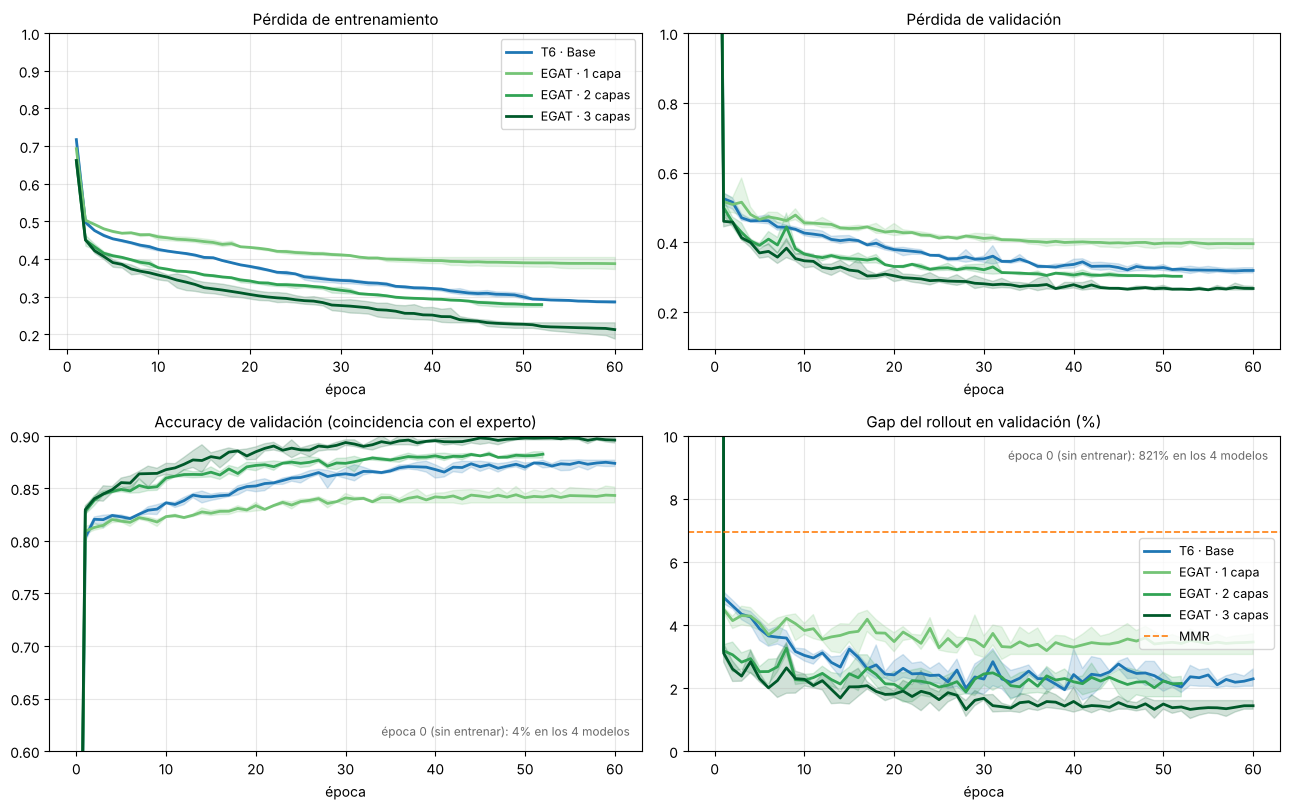

In [10]:
def curve(name, key):
    # matriz (semillas, épocas) rellenando con el último valor si alguna semilla se detuvo antes;
    # las métricas de validación incluyen la época 0 (modelo sin entrenar)
    hs = [H for _, H in RUNS[name]]
    L = max(len(H[key]) for H in hs)
    M = np.array([H[key] + [H[key][-1]] * (L - len(H[key])) for H in hs])
    if key in ("val_loss", "val_acc", "val_gap"):
        M = np.concatenate([np.array([[H["init"][key]] for H in hs]), M], axis=1)
        return np.arange(L + 1), M
    return np.arange(1, L + 1), M

fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))
panels = [("train_loss", "Pérdida de entrenamiento"), ("val_loss", "Pérdida de validación"),
          ("val_acc", "Accuracy de validación (coincidencia con el experto)"), ("val_gap", "Gap del rollout en validación (%)")]
for ax, (key, title) in zip(axes.flat, panels):
    for name in MODELOS:
        ep, M = curve(name, key)
        mean = np.nanmean(M, 0)
        ax.plot(ep, mean, color=COLORES[name], label=name, lw=2)
        if M.shape[0] > 1:
            ax.fill_between(ep, np.nanmin(M, 0), np.nanmax(M, 0), color=COLORES[name], alpha=0.18)
    ax.set_title(title, fontsize=11); ax.set_xlabel("época"); ax.grid(alpha=0.3)
axes[0, 0].set_ylim(top=1.0); axes[0, 1].set_ylim(top=1.0)
axes[1, 1].axhline(CRITERIO_MMR["gap_mmr_val"], color=COLORES["MMR"], ls="--", lw=1.2, label="MMR")
init_txt = {key: " · ".join(f"{CORTO[n]} {np.mean([H['init'][key] for _, H in RUNS[n]]) * (100 if key == 'val_acc' else 1):.0f}"
                            + ("%" if key in ("val_acc", "val_gap") else "") for n in MODELOS)
            for key in ("val_acc", "val_gap", "val_loss")}
for key in init_txt:                                   # si todos parten igual, se dice una vez
    vals = {t.split(" ", 1)[1] for t in init_txt[key].split(" · ")}
    if len(vals) == 1:
        init_txt[key] = f"{vals.pop()} en los {len(MODELOS)} modelos"
for ax, key in [(axes[1, 0], "val_acc"), (axes[1, 1], "val_gap")]:
    ax.text(0.98, 0.04 if key == "val_acc" else 0.96, "época 0 (sin entrenar): " + init_txt[key], transform=ax.transAxes,
            ha="right", va="bottom" if key == "val_acc" else "top", fontsize=8.5, color="dimgray")
axes[1, 1].set_ylim(0, max(10, CRITERIO_MMR["gap_mmr_val"] * 1.4))
axes[1, 0].set_ylim(0.6, 0.9)
axes[0, 0].legend(fontsize=9); axes[1, 1].legend(fontsize=9, loc="center right")
plt.tight_layout(); guardar(fig, "convergencia"); plt.show()

In [11]:
def first_epoch(values, cond):
    for k, v in enumerate(values, start=1):
        if cond(v):
            return k
    return None

CONV = {}
print("Épocas (una por semilla) hasta cada umbral; 'min' = minutos de reloj hasta gap val < 3 % (media de las semillas)")
print(f"{'Modelo':<16} {'gap ép. 0':>9} {'gap<MMR':>9} {'gap<3 %':>12} {'loss<0,35':>12} {'mejor época':>12} "
      f"{'mejor loss val':>15} {'oscil. gap':>10} {'s/época':>8} {'min':>5}")
for name in MODELOS:
    hs = [H for _, H in RUNS[name]]
    g0 = np.mean([H["init"]["val_gap"] for H in hs])
    e_gap = [first_epoch(H["val_gap"], lambda v: v < CRITERIO_MMR["gap_mmr_val"]) for H in hs]
    e_gap3 = [first_epoch(H["val_gap"], lambda v: v < 3.0) for H in hs]
    e_l35 = [first_epoch(H["val_loss"], lambda v: v < 0.35) for H in hs]
    e_acc = [first_epoch(H["val_acc"], lambda v: v >= 0.85) for H in hs]
    best_l = [H["val_loss"][H["best_epoch"] - 1] for H in hs]
    osc = [np.mean(np.abs(np.diff(H["val_loss"][-10:]))) for H in hs]          # |Δ loss val| medio, últimas 10 épocas
    osc_g = [np.mean(np.abs(np.diff(H["val_gap"][-10:]))) for H in hs]        # |Δ gap val| medio, últimas 10 épocas
    sec = [H["time"][-1] / H["epochs"] for H in hs]
    min_gap3 = [e * s / 60 for e, s in zip(e_gap3, sec) if e is not None]
    CONV[name] = {"gap_init": float(g0), "epoch_gap_below_mmr": e_gap, "epoch_gap_below_3": e_gap3,
                  "epoch_loss_below_035": e_l35, "epoch_acc_085": e_acc,
                  "best_epoch": [H["best_epoch"] for H in hs], "epochs": [H["epochs"] for H in hs],
                  "best_val_loss_mean": float(np.mean(best_l)), "best_val_loss_std": float(np.std(best_l)),
                  "best_val_acc": [H["val_acc"][H["best_epoch"] - 1] for H in hs],
                  "best_val_gap": [H["val_gap"][H["best_epoch"] - 1] for H in hs],
                  "oscillation": float(np.mean(osc)), "oscillation_gap": float(np.mean(osc_g)),
                  "sec_per_epoch": float(np.mean(sec)), "minutes_to_gap3": float(np.mean(min_gap3)) if min_gap3 else None,
                  "train_minutes": [H["time"][-1] / 60 for H in hs]}
    print(f"{name:<16} {g0:>8.1f}% {str(e_gap):>9} {str(e_gap3):>12} {str(e_l35):>12} {str(CONV[name]['best_epoch']):>12} "
          f"{np.mean(best_l):>7.3f} ± {np.std(best_l):.3f} {np.mean(osc_g):>10.2f} {np.mean(sec):>8.1f} "
          f"{np.mean(min_gap3) if min_gap3 else float('nan'):>5.1f}")

Épocas (una por semilla) hasta cada umbral; 'min' = minutos de reloj hasta gap val < 3 % (media de las semillas)
Modelo           gap ép. 0   gap<MMR      gap<3 %    loss<0,35  mejor época  mejor loss val oscil. gap  s/época   min
T6 · Base           821.0% [1, 1, 1] [10, 11, 13] [26, 28, 32] [51, 53, 46]   0.317 ± 0.006       0.22      4.2   0.8
EGAT · 1 capa       821.0% [1, 1, 1] [None, 30, None] [None, None, None] [55, 25, 42]   0.394 ± 0.012       0.23      3.4   1.7
EGAT · 2 capas      821.0% [1, 1, 1]    [3, 2, 5] [12, 19, 16] [44, 43, 40]   0.301 ± 0.002       0.29      4.7   0.3
EGAT · 3 capas      821.0% [1, 1, 1]    [2, 2, 1]   [9, 10, 7] [41, 55, 34]   0.262 ± 0.000       0.15      5.9   0.2


**Análisis de la convergencia.** Los cuatro modelos se entrenaron con la misma configuración y 3 semillas cada uno, y los cuatro parten igual (logits constantes: gap de 821 %).

- **Velocidad en épocas.** Más capas EGAT significa aprender más rápido. Después de la primera época, el gap de validación ya es 2,8–3,4 % con EGAT-3 y 3,0–3,4 % con EGAT-2, contra 4,7–5,1 % de la T6-Base. Para llegar a un gap < 3 %, EGAT-3 necesita 1–2 épocas, EGAT-2 2–5 y la T6-Base 10–13; EGAT-1 solo lo logra en una de sus tres semillas (época 30). Con la pérdida pasa lo mismo: baja de 0,35 en 7–10 épocas (EGAT-3), 12–19 (EGAT-2) y 26–32 (T6-Base); EGAT-1 nunca baja de 0,35.
- **Nivel final.** La mejor pérdida de validación es 0,262 ± 0,000 (EGAT-3), 0,301 ± 0,002 (EGAT-2), 0,317 ± 0,006 (T6-Base) y 0,394 ± 0,012 (EGAT-1); la accuracy, 89,1–90,0 %, 87,7–88,3 %, 87,3–87,5 % y 84,0–85,1 %. El gap de validación medio de las últimas 10 épocas es 1,40 %, 2,22 %, 2,28 % y 3,49 %.
- **Tiempo de reloj.** Cada capa EGAT agrega ≈ 1,2 s por época (3,4 s con 1 capa, 4,7 s con 2 y 5,9 s con 3; la T6-Base, 4,2 s). Aun así, como EGAT-3 converge en muchas menos épocas, es la que antes llega a un gap < 3 %: 0,2 min, contra 0,8 min de la T6-Base.
- **Estabilidad.** Las 12 corridas convergen sin divergencias. EGAT-3 es la más estable: sus 3 semillas terminan con la misma pérdida (desviación < 0,001) y su gap oscila menos entre épocas (0,15 pp, contra 0,22–0,29 pp de las demás). EGAT-1 es la que más varía entre semillas (una se detuvo por early stopping en la época 33) y su pérdida se aplana en ≈ 0,40, muy por encima de las demás. Las EGAT de 2 y 3 capas alcanzan su mejor época antes (entre la 34 y la 55) y 5 de sus 6 corridas se detienen antes de la época 60.

## 8. Punto 6 — Evaluación con instancias de distintos tamaños

Los modelos se entrenaron **solo con 10×8** y se evalúan sin cambios en 7 tamaños, de 5×4 a 100×80, con **las mismas instancias de la Tarea 6 y del proyecto del módulo 2** (30 por tamaño con semilla 3000 + W, y las 50 de prueba en 10×8). La referencia es el **experto ILS** de las tareas anteriores: $\text{gap} = 100\,(\text{costo}/\text{costo ILS} - 1)$. Evaluamos con el rollout greedy **los 3 modelos entrenados de cada arquitectura** y reportamos la media y la desviación estándar sobre semillas × instancias. Como referencias se incluyen MMR, un constructivo aleatorio, el modelo del módulo 2 y las variantes A y B de la Tarea 6 (cifras guardadas, mismas instancias).

Primero verificamos que el rollout batcheado coincide con el `GreedyAgent` de `eda` y que el encoder se ejecuta una sola vez por instancia.

In [12]:
class ModelEvalActions:
    # evaluador para el GreedyAgent de eda: encoder 1 vez por instancia (caché) y decoder en cada paso
    def __init__(self, model):
        self.model, self.cache, self.n_encoder_calls, self.n_decoder_calls = model, {}, 0, 0

    def __call__(self, states, env):
        single = not isinstance(states, list)
        if single:
            states = [states]
        evals = [[] for _ in states]
        groups = {}
        for k, s in enumerate(states):
            if not s.is_complete:
                groups.setdefault(s.inst_info.probs.shape, []).append(k)
        self.model.eval()
        with torch.no_grad():
            for (W, T), ks in groups.items():
                new = [states[k].inst_info for k in ks if id(states[k].inst_info) not in self.cache]
                if new:                                                        # ENCODER: solo instancias nuevas
                    enc = self.model.encode(torch.tensor(np.stack([i.probs for i in new]), dtype=torch.float32),
                                            torch.tensor(np.stack([i.values for i in new]), dtype=torch.float32))
                    self.n_encoder_calls += len(new)
                    for r, inst in enumerate(new):
                        self.cache[id(inst)] = (inst, {key: val[r] for key, val in enc.items()})
                enc = {key: torch.stack([self.cache[id(states[k].inst_info)][1][key] for k in ks])
                       for key in ("Hw", "Ht", "A", "Ep", "P", "V")}
                free = torch.tensor(np.array([[a < 0 for a in states[k].assignment] for k in ks]))
                q = torch.tensor(np.array([states[k].q for k in ks]), dtype=torch.float32)
                logp = torch.log_softmax(self.model.decode(enc, free[:, None], q[:, None])[:, 0], -1).tolist()   # DECODER
                self.n_decoder_calls += 1
                for r, k in enumerate(ks):
                    evals[k] = [(a, logp[r][a[1][0] * T + a[1][1]]) for a in env.gen_actions(states[k], "constructive")]
        return evals[0] if single else evals


for name, model in MODEL.items():
    ev = ModelEvalActions(model)
    c_agent = agent_costs(ev, test_insts)
    c_batch = rollout_costs(model, test_insts)
    assert np.allclose(c_agent, c_batch), name
    assert ev.n_encoder_calls == len(test_insts)
    print(f"{name:<14} GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: "
          f"{ev.n_encoder_calls} (1 por instancia) | llamadas al decoder: {ev.n_decoder_calls} (1 por paso)")

T6 · Base      GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)
EGAT · 1 capa  GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)
EGAT · 2 capas GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)
EGAT · 3 capas GreedyAgent de eda == rollout batcheado en las 50 de prueba ✔ | llamadas al encoder: 50 (1 por instancia) | llamadas al decoder: 10 (1 por paso)


In [13]:
SIZES = [(5, 4), (10, 8), (15, 10), (20, 15), (30, 20), (50, 40), (100, 80)]
if RAPIDO:
    SIZES = SIZES[:5]
N_SIZE = 30
# cifras del proyecto del módulo 2 en estas mismas instancias (figuras_proyecto/resultados.json)
REF_MODULO2 = {"5×4": (1.671, 4.209), "10×8": (2.968, 3.683), "15×10": (5.279, 3.872), "20×15": (3.990, 3.053),
               "30×20": (5.301, 2.886)}
REF_T6 = {"5×4": {"Base": [0.709, 2.609], "A": [0.997, 3.363], "B": [1.298, 3.995]}, "10×8": {"Base": [2.334, 2.929], "A": [2.438, 2.963], "B": [2.212, 3.13]}, "15×10": {"Base": [3.128, 2.574], "A": [3.398, 2.742], "B": [3.25, 3.027]}, "20×15": {"Base": [1.956, 1.687], "A": [2.094, 1.581], "B": [2.008, 1.864]}, "30×20": {"Base": [2.949, 1.868], "A": [2.973, 1.98], "B": [3.432, 1.902]}, "50×40": {"Base": [2.015, 0.997], "A": [1.964, 1.038], "B": [1.861, 1.026]}, "100×80": {"Base": [1.572, 0.787], "A": [1.521, 0.603], "B": [1.298, 0.706]}}   # Tarea 6 (figuras_t6): media y desv. de Base, A y B
REF_MMR_MODULO2 = {"5×4": 6.458, "10×8": 7.682, "15×10": 7.821, "20×15": 5.713, "30×20": 5.889}

SIZE_SETS, COSTS, EVAL_SEEDS, EVAL, EVAL_TIME = {}, {}, {}, {}, {}
for (W, T) in SIZES:
    label = f"{W}×{T}"
    t0 = time.time()
    if (W, T) == (N_WEAPONS, N_TARGETS):
        insts, exp_c = test_insts, test_expert                   # ya resueltas; medimos el tiempo del ILS aparte
        for k, inst in enumerate(insts):
            ils(inst, rng=np.random.default_rng(k))
    else:
        solved = solve_instances(W, T, N_SIZE, seed=3000 + W)
        insts, exp_c = [i for i, _, _ in solved], np.array([c for _, _, c in solved])
    t_ils = (time.time() - t0) / len(insts)
    SIZE_SETS[label] = (insts, exp_c)
    costs, tms = {}, {"Experto ILS": 1e3 * t_ils}
    for name in MODELOS:                               # los modelos de las 3 semillas de cada arquitectura
        costs[name] = []
        for s, (m, _) in enumerate(RUNS[name]):
            t1 = time.time(); costs[name].append(rollout_costs(m, insts))
            if s == 0:
                tms[name] = 1e3 * (time.time() - t1) / len(insts)
    t1 = time.time(); costs["MMR"] = [np.array([cost_of(i, mmr(i)) for i in insts])]
    tms["MMR"] = 1e3 * (time.time() - t1) / len(insts)
    costs["Aleatorio"] = [agent_costs(make_random_eval(W), insts)]
    COSTS[label] = costs
    EVAL_SEEDS[label] = {n: [gap(c, exp_c) for c in cs] for n, cs in costs.items()}     # un arreglo por semilla
    EVAL[label] = {n: np.concatenate(gs) for n, gs in EVAL_SEEDS[label].items()}         # semillas × instancias
    EVAL_TIME[label] = tms
    print(f"{label:>7}: {len(insts)} instancias · experto {t_ils:6.2f} s/inst · " +
          " | ".join(f"{n} {EVAL[label][n].mean():6.2f}%" for n in list(MODELOS) + ["MMR"]), flush=True)
    if label in REF_MMR_MODULO2:                       # mismas instancias y mismo experto que el proyecto
        assert abs(EVAL[label]["MMR"].mean() - REF_MMR_MODULO2[label]) < 1e-2, label
print("✔ El gap de MMR coincide con el del proyecto del módulo 2 en los 5 tamaños compartidos (mismas instancias y experto)")

# ¿Qué tan buena es la referencia en los tamaños grandes? ILS 20 veces más largo y con perturbación proporcional a W
REF_LARGA = {}
for label in ("30×20", "50×40", "100×80"):
    if label not in SIZE_SETS:
        continue
    insts, exp_c = SIZE_SETS[label]
    W = int(label.split("×")[0])
    long_c = np.array([ils(i, n_iter=2000, k_perturb=max(3, W // 10), rng=np.random.default_rng(100 + k))[1]
                       for k, i in enumerate(insts)])
    REF_LARGA[label] = {"mejora_ils_largo": float(-gap(long_c, exp_c).mean()),
                        "gap_vs_ils_largo": {n: float(np.mean([gap(c, long_c).mean() for c in COSTS[label][n]]))
                                             for n in list(MODELOS) + ["MMR"]}}
    print(f"{label:>7}: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en {REF_LARGA[label]['mejora_ils_largo']:.2f}% "
          "| gap vs ILS largo: " + " | ".join(f"{n} {g_:.2f}%" for n, g_ in REF_LARGA[label]["gap_vs_ils_largo"].items()))

    5×4: 30 instancias · experto   0.01 s/inst · T6 · Base   0.71% | EGAT · 1 capa   1.68% | EGAT · 2 capas   1.80% | EGAT · 3 capas   0.35% | MMR   6.46%


   10×8: 50 instancias · experto   0.01 s/inst · T6 · Base   2.33% | EGAT · 1 capa   4.17% | EGAT · 2 capas   2.36% | EGAT · 3 capas   1.54% | MMR   7.68%


  15×10: 30 instancias · experto   0.01 s/inst · T6 · Base   3.13% | EGAT · 1 capa   4.15% | EGAT · 2 capas   3.71% | EGAT · 3 capas   3.64% | MMR   7.82%


  20×15: 30 instancias · experto   0.01 s/inst · T6 · Base   1.96% | EGAT · 1 capa   3.37% | EGAT · 2 capas   2.22% | EGAT · 3 capas   1.65% | MMR   5.71%


  30×20: 30 instancias · experto   0.02 s/inst · T6 · Base   2.95% | EGAT · 1 capa   4.21% | EGAT · 2 capas   3.71% | EGAT · 3 capas   3.56% | MMR   5.89%


  50×40: 30 instancias · experto   0.02 s/inst · T6 · Base   2.01% | EGAT · 1 capa   2.17% | EGAT · 2 capas   1.77% | EGAT · 3 capas   1.12% | MMR   2.46%


 100×80: 30 instancias · experto   0.04 s/inst · T6 · Base   1.57% | EGAT · 1 capa   1.35% | EGAT · 2 capas   1.24% | EGAT · 3 capas   0.67% | MMR   1.23%


✔ El gap de MMR coincide con el del proyecto del módulo 2 en los 5 tamaños compartidos (mismas instancias y experto)


  30×20: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en 0.82% | gap vs ILS largo: T6 · Base 3.80% | EGAT · 1 capa 5.07% | EGAT · 2 capas 4.56% | EGAT · 3 capas 4.41% | MMR 6.76%


  50×40: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en 1.07% | gap vs ILS largo: T6 · Base 3.12% | EGAT · 1 capa 3.28% | EGAT · 2 capas 2.88% | EGAT · 3 capas 2.22% | MMR 3.58%


 100×80: el ILS largo (2 000 iteraciones) mejora al ILS de referencia en 0.93% | gap vs ILS largo: T6 · Base 2.53% | EGAT · 1 capa 2.31% | EGAT · 2 capas 2.20% | EGAT · 3 capas 1.62% | MMR 2.18%


In [14]:
COLS = list(MODELOS) + ["MMR", "Aleatorio"]


def vs_mmr(label, name):
    # compara instancia a instancia con MMR (el arreglo de MMR se repite una vez por semilla)
    g, g_mmr = EVAL[label][name], EVAL[label]["MMR"]
    g_mmr = np.tile(g_mmr, len(g) // len(g_mmr))
    return 100 * np.mean(g < g_mmr - 1e-9), 100 * np.mean(np.abs(g - g_mmr) <= 1e-9)


print("Gap vs experto ILS (%), media ± desviación estándar sobre semillas × instancias "
      f"({N_SEEDS} semillas por arquitectura; MMR y aleatorio son deterministas)")
print(f"{'Tamaño':<8} {'W·T':>5} " + " ".join(f"{c:>16}" for c in COLS) + f" {'Módulo 2 (ref.)':>16}"
      + f" {'T6 · A (ref.)':>16} {'T6 · B (ref.)':>16}")
for label, d in EVAL.items():
    W, T = map(int, label.split("×"))
    ref = REF_MODULO2.get(label)
    print(f"{label:<8} {W * T:>5} " + " ".join(f"{d[c].mean():>8.2f} ± {d[c].std():<5.2f}" for c in COLS)
          + (f" {ref[0]:>8.2f} ± {ref[1]:<5.2f}" if ref else f" {'—':>16}")
          + "".join(f" {REF_T6[label][k][0]:>8.2f} ± {REF_T6[label][k][1]:<5.2f}" if label in REF_T6 else f" {'—':>16}"
                    for k in ("A", "B")))

print("\nGap medio de cada semilla (%) y variación entre semillas:")
print(f"{'Tamaño':<8} " + " ".join(f"{CORTO[n] + ' (s0 / s1 / s2)':>30} {'media ± desv.':>14}" for n in MODELOS))
for label in EVAL:
    row = f"{label:<8} "
    for n in MODELOS:
        ms = [g.mean() for g in EVAL_SEEDS[label][n]]
        row += f"{' / '.join(f'{v:.2f}' for v in ms):>30} {np.mean(ms):>6.2f} ± {np.std(ms):<5.2f}"
    print(row)

print(f"\nDetalle en las 50 instancias de prueba 10×8 ({N_SEEDS} semillas × 50 = {N_SEEDS * 50} ejecuciones por arquitectura):")
print(f"{'Método':<16} {'gap medio':>10} {'desv.':>7} {'mediana':>8} {'% óptimo':>9} {'gana a MMR':>11} {'empata':>7}")
for c in COLS:
    g = EVAL["10×8"][c]
    wins, ties = vs_mmr("10×8", c)
    print(f"{c:<16} {g.mean():>9.2f}% {g.std():>7.2f} {np.median(g):>7.2f}% {100 * np.mean(g < 1e-6):>8.0f}% "
          f"{wins:>10.0f}% {ties:>6.0f}%")

print("\nTiempo de inferencia por instancia (ms; rollout batcheado del modelo de la semilla 0, todos los hilos):")
print(f"{'Tamaño':<8} " + " ".join(f"{c:>14}" for c in list(MODELOS) + ["MMR", "Experto ILS"]))
for label, t in EVAL_TIME.items():
    print(f"{label:<8} " + " ".join(f"{t[c]:>14.2f}" for c in list(MODELOS) + ["MMR", "Experto ILS"]))

Gap vs experto ILS (%), media ± desviación estándar sobre semillas × instancias (3 semillas por arquitectura; MMR y aleatorio son deterministas)
Tamaño     W·T        T6 · Base    EGAT · 1 capa   EGAT · 2 capas   EGAT · 3 capas              MMR        Aleatorio  Módulo 2 (ref.)    T6 · A (ref.)    T6 · B (ref.)
5×4         20     0.71 ± 2.61      1.68 ± 4.22      1.80 ± 4.35      0.35 ± 1.25      6.46 ± 7.87    258.79 ± 102.08     1.67 ± 4.21      1.00 ± 3.36      1.30 ± 4.00 
10×8        80     2.33 ± 2.93      4.17 ± 3.93      2.36 ± 3.21      1.54 ± 2.48      7.68 ± 4.91    316.20 ± 100.12     2.97 ± 3.68      2.44 ± 2.96      2.21 ± 3.13 
15×10      150     3.13 ± 2.57      4.15 ± 3.67      3.71 ± 2.74      3.64 ± 2.77      7.82 ± 4.92    454.33 ± 159.71     5.28 ± 3.87      3.40 ± 2.74      3.25 ± 3.03 
20×15      300     1.96 ± 1.69      3.37 ± 2.44      2.22 ± 1.68      1.65 ± 1.82      5.71 ± 3.11    373.09 ± 89.88     3.99 ± 3.05      2.09 ± 1.58      2.01 ± 1.86 
30×20      6

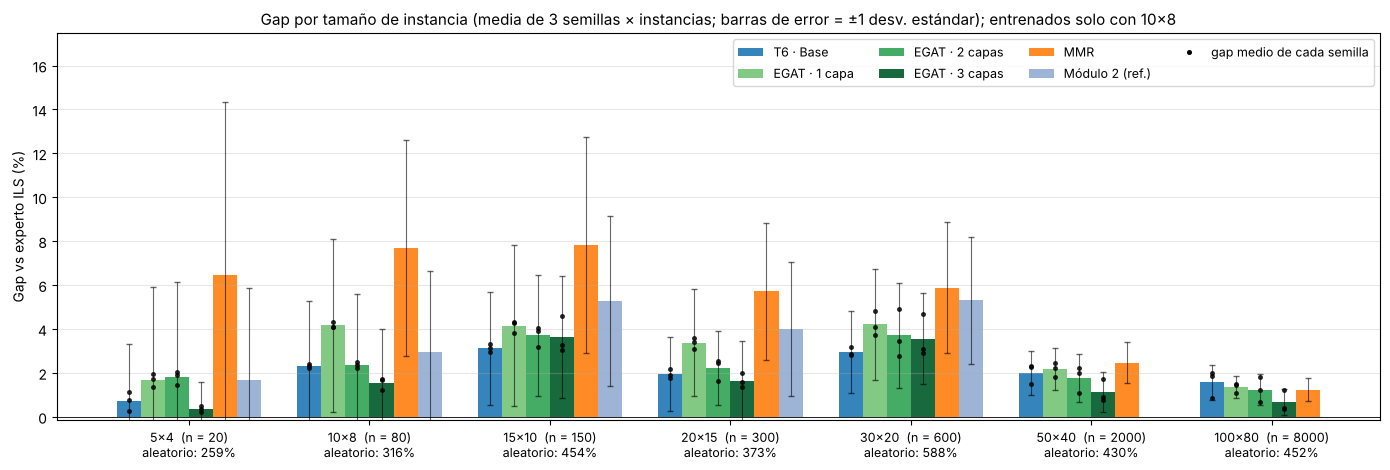

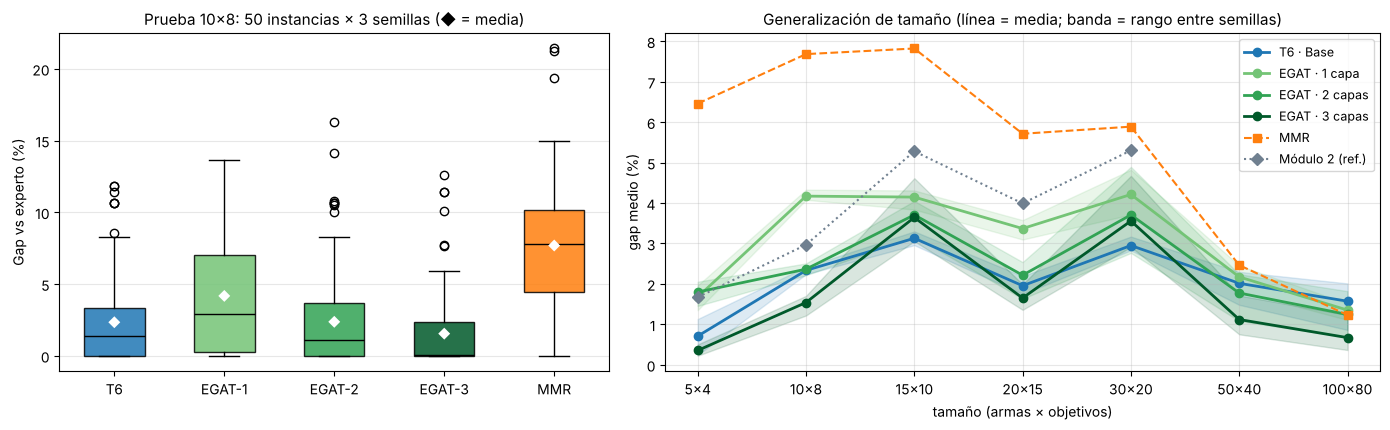

In [15]:
labels = list(EVAL)
fig, ax = plt.subplots(figsize=(14, 4.8))
series = list(MODELOS) + ["MMR"]
width = 0.8 / (len(series) + 1)
x = np.arange(len(labels))
for k, name in enumerate(series):
    means = [EVAL[l][name].mean() for l in labels]; stds = [EVAL[l][name].std() for l in labels]
    xs = x + (k - len(series) / 2) * width
    ax.bar(xs, means, width, yerr=stds, capsize=2.5, color=COLORES[name],
           label=name, alpha=0.9, error_kw=dict(lw=0.8, alpha=0.6))
    if name in MODELOS:                                # gap medio de cada semilla
        for xk, l in zip(xs, labels):
            ax.plot([xk] * len(EVAL_SEEDS[l][name]), [g.mean() for g in EVAL_SEEDS[l][name]], "o", color="black",
                    ms=2.6, alpha=0.75, zorder=3)
ref_x = [k for k, l in enumerate(labels) if l in REF_MODULO2]
ax.bar(np.array(ref_x) + (len(series) / 2) * width, [REF_MODULO2[labels[k]][0] for k in ref_x], width,
       yerr=[REF_MODULO2[labels[k]][1] for k in ref_x], capsize=2.5, color=COLORES["Módulo 2"], label="Módulo 2 (ref.)",
       error_kw=dict(lw=0.8, alpha=0.6))
ax.plot([], [], "o", color="black", ms=2.6, label="gap medio de cada semilla")
ax.axhline(0, color="k", lw=0.6)
ax.set_xticks(x)
ax.set_xticklabels([f"{l}  (n = {int(l.split('×')[0]) * int(l.split('×')[1])})\naleatorio: {EVAL[l]['Aleatorio'].mean():.0f}%"
                    for l in labels], fontsize=9)
top = max(EVAL[l][n].mean() + EVAL[l][n].std() for l in labels for n in series)
ax.set_ylabel("Gap vs experto ILS (%)")
ax.set_ylim(min(0, min(EVAL[l][n].mean() for l in labels for n in series) - 0.5), top * 1.22)
ax.set_title(f"Gap por tamaño de instancia (media de {N_SEEDS} semillas × instancias; barras de error = ±1 desv. estándar); "
             "entrenados solo con 10×8", fontsize=11)
hs_, ls_ = ax.get_legend_handles_labels()
order = [k for k, t in enumerate(ls_) if t != "gap medio de cada semilla"] + [ls_.index("gap medio de cada semilla")]
ax.legend([hs_[k] for k in order], [ls_[k] for k in order], ncol=4, fontsize=9, loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); guardar(fig, "tamanos"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})
data = [EVAL["10×8"][c] for c in series]
bp = axes[0].boxplot(data, tick_labels=[CORTO.get(s, s) for s in series], patch_artist=True, widths=0.55,
                     medianprops=dict(color="black"))
for patch, name in zip(bp["boxes"], series):
    patch.set_facecolor(COLORES[name]); patch.set_alpha(0.85)
for k, g in enumerate(data, start=1):
    axes[0].text(k, g.mean(), "◆", ha="center", va="center", color="white", fontsize=9)
axes[0].set_ylabel("Gap vs experto (%)")
axes[0].set_title(f"Prueba 10×8: 50 instancias × {N_SEEDS} semillas (◆ = media)", fontsize=11)
axes[0].grid(axis="y", alpha=0.3)
for name in MODELOS:
    seed_means = np.array([[g.mean() for g in EVAL_SEEDS[l][name]] for l in labels])     # (tamaños, semillas)
    axes[1].plot(x, [EVAL[l][name].mean() for l in labels], "o-", color=COLORES[name], label=name, lw=2)
    if seed_means.shape[1] > 1:
        axes[1].fill_between(x, seed_means.min(1), seed_means.max(1), color=COLORES[name], alpha=0.15)
axes[1].plot(x, [EVAL[l]["MMR"].mean() for l in labels], "s--", color=COLORES["MMR"], label="MMR")
axes[1].plot(ref_x, [REF_MODULO2[labels[k]][0] for k in ref_x], "D:", color="slategray", label="Módulo 2 (ref.)")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels); axes[1].set_xlabel("tamaño (armas × objetivos)")
axes[1].set_ylabel("gap medio (%)")
axes[1].set_title("Generalización de tamaño (línea = media; banda = rango entre semillas)", fontsize=11)
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout(); guardar(fig, "comparacion"); plt.show()

**Análisis de la evaluación.** Cada arquitectura se evalúa con sus 3 modelos entrenados (uno por semilla) en las mismas instancias de la Tarea 6.

- **Tamaño de entrenamiento (10×8).** EGAT-3 logra el menor gap: 1,54 % (mediana 0,08 %; iguala al experto en el 47 % de las ejecuciones y le gana a MMR en el 83 %), contra 2,33 % de la T6-Base, 2,36 % de EGAT-2 y 4,17 % de EGAT-1. También mejora a las variantes A y B de la Tarea 6 (2,44 % y 2,21 %).
- **Generalización de tamaño.** EGAT-3 es la mejor en 5 de los 7 tamaños (5×4, 10×8, 20×15, 50×40 y 100×80) y su gap promedio en los 7 tamaños es 1,79 %, contra 2,09 % de la T6-Base. En 100×80 es el primero de nuestros modelos que supera a MMR en promedio (0,67 % vs 1,23 %; le gana en el 78 % de las ejecuciones). Pero en 15×10 y 30×20 la T6-Base sigue siendo mejor (3,13 % y 2,95 %, contra 3,64 % y 3,56 %), y ahí EGAT-3 varía más entre semillas (rangos 3,06–4,61 % y 2,91–4,67 %).
- **Las otras profundidades.** EGAT-1 es la peor en 5 de los 7 tamaños, y EGAT-2 queda cerca de la T6-Base: mejor en 50×40 y 100×80, peor entre 5×4 y 30×20.
- **Contra un ILS más largo** (2 000 iteraciones, que mejora a la referencia en 0,8–1,1 % en los tres tamaños más grandes), el orden no cambia: en 100×80, EGAT-3 queda a 1,62 % y MMR a 2,18 %.
- **Tiempo.** En 10×8 los cuatro modelos resuelven una instancia en 0,3–0,5 ms (el experto tarda 11 ms): como el encoder se calcula una sola vez, sus capas extra casi no se notan. En 100×80, en cambio, todos tardan 146–162 ms, más que el experto (45 ms).

## 9. Punto 4 — Ablación de profundidad: ¿cuántos saltos necesita el encoder?

Cada capa EGAT extiende el campo receptivo en un salto (sección 5: con 1 capa, el gradiente del embedding de un arma respecto de las aristas de las otras armas es exactamente 0). En el grafo bipartito completo:

| Capas $L$ | Lo que "ve" un arma al salir del encoder | Lo que "ve" un objetivo |
|---|---|---|
| 1 | los objetivos que puede atacar: sus valores y sus propias $p_{ij}$ | las armas que lo pueden atacar, a través de $p_{ij}$ |
| 2 | además, las otras armas que compiten por esos objetivos (2 saltos) | además, los otros objetivos que esas armas pueden atacar |
| 3 | ningún nodo nuevo (el diámetro es 2), pero una combinación más | ídem |

Además, el decoder mezcla información global en cada paso (promedios y glimpse sobre todas las armas libres y los objetivos), así que incluso con 1 capa el modelo completo puede relacionar armas entre sí; lo que cambia es si esa relación ya viene en los embeddings del encoder.

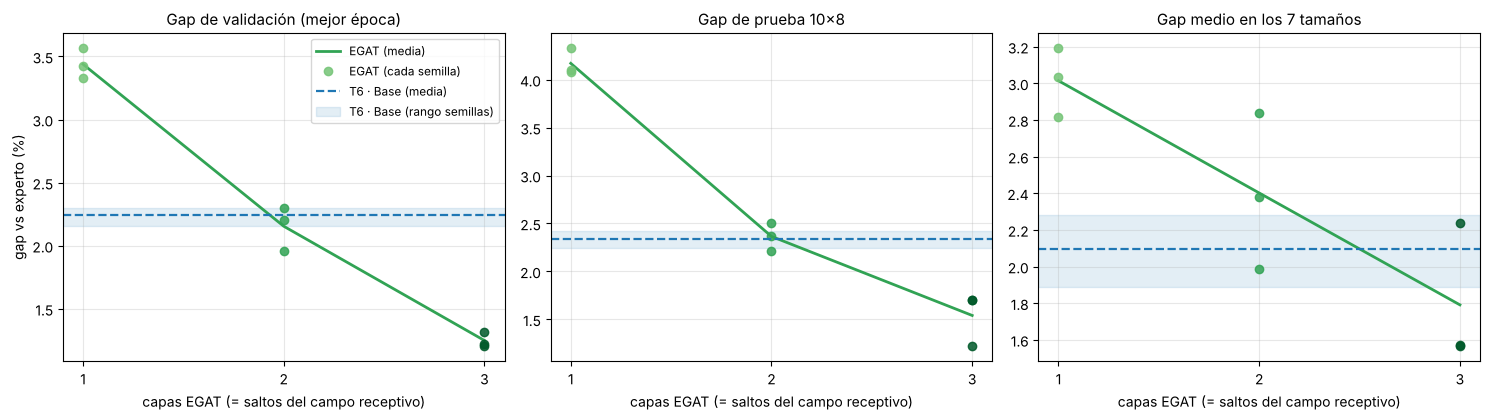

Modelo           parámetros  encoder  s/época  mejor loss val      gap val %     gap 10×8 %    gap medio %
T6 · Base           192 656  133 840      4.2    0.317 ± 0.006    2.24 ± 0.06    2.33 ± 0.08    2.09 ± 0.16
EGAT · 1 capa       118 016   59 200      3.4    0.394 ± 0.012    3.44 ± 0.10    4.17 ± 0.11    3.01 ± 0.15
EGAT · 2 capas      177 024  118 208      4.7    0.301 ± 0.002    2.15 ± 0.14    2.36 ± 0.12    2.40 ± 0.35
EGAT · 3 capas      236 032  177 216      5.9    0.262 ± 0.000    1.25 ± 0.05    1.54 ± 0.23    1.79 ± 0.32


In [16]:
EGATS = [n for n in MODELOS if MODELOS[n]["encoder"] == "egat"]
Ls = [MODELOS[n]["n_layers"] for n in EGATS]
best_gap = {n: [H["val_gap"][H["best_epoch"] - 1] for _, H in RUNS[n]] for n in MODELOS}
best_loss = {n: [H["val_loss"][H["best_epoch"] - 1] for _, H in RUNS[n]] for n in MODELOS}
test10 = {n: [g.mean() for g in EVAL_SEEDS["10×8"][n]] for n in MODELOS}
avg_sizes = {n: [float(np.mean([EVAL_SEEDS[l][n][s].mean() for l in EVAL])) for s in range(N_SEEDS)] for n in MODELOS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
panels = [("Gap de validación (mejor época)", best_gap), ("Gap de prueba 10×8", test10),
          (f"Gap medio en los {len(EVAL)} tamaños", avg_sizes)]
for ax, (title, data) in zip(axes, panels):
    ax.plot(Ls, [np.mean(data[n]) for n in EGATS], "-", color=COLORES["EGAT · 2 capas"], lw=2, label="EGAT (media)")
    for L, n in zip(Ls, EGATS):
        ax.plot([L] * len(data[n]), data[n], "o", color=COLORES[n], ms=6, alpha=0.85,
                label="EGAT (cada semilla)" if L == Ls[0] else None)
    ref = data["T6 · Base"]
    ax.axhline(np.mean(ref), color=COLORES["T6 · Base"], ls="--", lw=1.6, label="T6 · Base (media)")
    ax.axhspan(min(ref), max(ref), color=COLORES["T6 · Base"], alpha=0.12, label="T6 · Base (rango semillas)")
    ax.set_xticks(Ls); ax.set_xlabel("capas EGAT (= saltos del campo receptivo)"); ax.set_title(title, fontsize=11)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("gap vs experto (%)"); axes[0].legend(fontsize=8.5)
plt.tight_layout(); guardar(fig, "profundidad"); plt.show()

ABLACION = {}
print(f"{'Modelo':<16} {'parámetros':>10} {'encoder':>8} {'s/época':>8} {'mejor loss val':>15} {'gap val %':>14} "
      f"{'gap 10×8 %':>14} {'gap medio %':>14}")
for n in MODELOS:
    ABLACION[n] = {"capas": MODELOS[n]["n_layers"], "params": PARAMS[n][0], "params_encoder": PARAMS[n][1],
                   "sec_per_epoch": CONV[n]["sec_per_epoch"],
                   "best_val_loss": best_loss[n], "best_val_gap": best_gap[n], "test10_seed_means": test10[n],
                   "avg_sizes_seed_means": avg_sizes[n]}
    print(f"{n:<16} {PARAMS[n][0]:>10,} {PARAMS[n][1]:>8,} {CONV[n]['sec_per_epoch']:>8.1f} "
          f"{np.mean(best_loss[n]):>8.3f} ± {np.std(best_loss[n]):.3f} {np.mean(best_gap[n]):>7.2f} ± {np.std(best_gap[n]):.2f} "
          f"{np.mean(test10[n]):>7.2f} ± {np.std(test10[n]):.2f} {np.mean(avg_sizes[n]):>7.2f} ± {np.std(avg_sizes[n]):.2f}"
          .replace(",", " "))

**Análisis de la ablación.** - **1 capa (1 salto) no alcanza.** Con 1 capa, cada arma solo conoce los objetivos y sus propias probabilidades, pero no a las armas con las que compite. Aunque el decoder mezcla información de todas las armas en cada paso, EGAT-1 queda muy atrás: gap de validación 3,44 % y de prueba 4,17 % (10×8), contra 2,15 % y 2,36 % con 2 capas. La competencia entre armas tiene que venir ya en los vectores del encoder.
- **2 capas (2 saltos) cubren el grafo.** Con 2 saltos cada arma ya conoce a las armas que compiten por sus objetivos (el diámetro de $K_{W,T}$ es 2). EGAT-2 queda al nivel de la T6-Base, que también tiene 2 capas (2,36 % vs 2,33 % en 10×8): a igual profundidad, cambiar la atención por producto punto por la atención aditiva de la EGAT no cambia mucho la calidad, aunque sí acelera el aprendizaje (sección 7).
- **3 capas: ningún nodo nuevo, pero sí caminos nuevos.** Una 3.ª capa no alcanza nodos nuevos, pero sí información nueva: por el camino arma → objetivo → arma → objetivo, cada arma sabe qué otras opciones tienen sus rivales, es decir, si a ellos les conviene más atacar otro objetivo. Es la mejora más grande: gap de validación 1,25 % (44 % menos que la T6-Base) y de prueba 1,54 % en 10×8, con la menor pérdida y la convergencia más rápida.
- **Costo y limitación.** Cada capa agrega ≈ 59 000 parámetros y ≈ 1,2 s por época. EGAT-3 tiene más parámetros que la T6-Base (236 000 vs 193 000) y no entrenamos una T6-Base de 3 capas, así que no podemos separar del todo el efecto de la profundidad del de la EGAT; la comparación a igual profundidad (EGAT-2 vs T6-Base) sugiere que lo decisivo es la profundidad.

## 10. Discusión y conclusiones

1. **El WTAP como grafo.** Un grafo bipartito armas–objetivos, con la probabilidad de impacto en las aristas, representa el problema sin depender del tamaño ni del orden, y sus aristas coinciden con las acciones del decoder.
2. **EGAT, no GAT.** Como las armas no tienen features propias, una GAT no las puede distinguir (distancia 0 entre sus vectores); la EGAT sí, gracias a las aristas. A igual profundidad (2 capas), rinde como el encoder de la Tarea 6 y aprende más rápido.
3. **La profundidad es lo que más importa.** 1 salto no basta (gap 4,17 % en 10×8), 2 saltos igualan a la Tarea 6 (2,36 %) y 3 capas dan el mejor modelo que hemos entrenado (1,54 % en 10×8, 1,79 % de promedio en los 7 tamaños y, por primera vez, mejor que MMR en 100×80), a cambio de ≈ 40 % más tiempo por época que la T6-Base.
4. **Pendiente.** En 15×10 y 30×20 la T6-Base sigue siendo mejor y EGAT-3 varía más entre semillas. Falta separar el efecto de la profundidad del de la EGAT (entrenando una T6-Base de 3 capas) y probar 4 capas.
5. **Recomendación.** Usar la EGAT de 3 capas como nuevo modelo base.

In [17]:
summary = {
    "grafo": GRAFO, "gat_check": GAT_CHECK, "campo_receptivo": CAMPO, "criterio_mmr": CRITERIO_MMR,
    "params": {name: PARAMS[name][0] for name in MODELOS}, "params_encoder": {name: PARAMS[name][1] for name in MODELOS},
    "modelos": MODELOS, "train_cfg": TRAIN_CFG, "n_seeds": N_SEEDS, "n_train": N_TRAIN,
    "n_train_decisions": int(D_train["Y"].numel()), "n_val_decisions": int(D_val["Y"].numel()),
    "histories": {name: [{k: H[k] for k in ("train_loss", "val_loss", "train_acc", "val_acc", "val_gap",
                                             "lr", "time", "best_epoch", "epochs", "init")} for _, H in RUNS[name]]
                  for name in MODELOS},
    "reproduce_t6": bool(REPRODUCE_T6), "ref_t6_hist": REF_T6_HIST,
    "convergence": CONV,
    "eval": {label: {n: {"mean": float(g.mean()), "std": float(g.std()), "median": float(np.median(g)),
                         "pct_optimal": float(100 * np.mean(g < 1e-6)),
                         "wins_vs_mmr": float(vs_mmr(label, n)[0]), "ties_vs_mmr": float(vs_mmr(label, n)[1]),
                         "n": int(len(g)), "n_instances": int(len(EVAL_SEEDS[label][n][0])),
                         "seed_means": [float(s.mean()) for s in EVAL_SEEDS[label][n]],
                         "seed_std": float(np.std([s.mean() for s in EVAL_SEEDS[label][n]]))}
                     for n, g in d.items()} for label, d in EVAL.items()},
    "eval_time_ms": EVAL_TIME,
    "ref_modulo2": REF_MODULO2, "ref_t6": REF_T6, "ref_ils_largo": REF_LARGA,
    "ablacion": ABLACION,
}
with open("figuras_t7/resultados.json", "w") as f:
    json.dump(summary, f, indent=1, ensure_ascii=False, default=float)
print("Resultados guardados en figuras_t7/resultados.json")
# pesos de los 12 modelos entrenados, por si se quiere re-evaluar sin re-entrenar
torch.save({name: [m.state_dict() for m, _ in RUNS[name]] for name in MODELOS}, "modelos_t7.pt")
print("Pesos guardados en modelos_t7.pt")

Resultados guardados en figuras_t7/resultados.json
Pesos guardados en modelos_t7.pt
